# 02 — 2024 HLT efficiency with the new eta-R9 map: comparisons and map study

Created 2026-10-03. Class: deliverable (plots for `slides/hlt_2024_etaR9_map_comparison.tex`).

**Three efficiency sets, nominal fit `bwDscbCms` only**
- **2023 postBPix** — `data/inputs/repo2023_9450e11_{normal,fullPath}.csv`, from `github.com/santanumahata/HLT-diphoton-efficiency-2023-results` @ `9450e11`.
- **2024 without NF** (`repo` in the code) — `data/inputs/repo2024_d422813_efficiencies_from_txt.csv`, eras `etaR9rw_withPresel[_fullPath]`, from `github.com/santanumahata/HLT-diphoton-efficiency-2024-results` @ `d422813`; weights from `2024_R9_vs_eta_HggOverDY_presel_vf.root` ("old map").
- **2024 with NF** (`local` in the code) — `data/inputs/new_results/HLT_2024_withPresel[_fullPath]_SS/*/egammaEffi.txt`, fits run on lxplus 2026-10-01/02 with weights from `2024Lowmass_R9_vs_eta_ratio_presel.root` ("new map").

**Map study inputs**: both map files (`data/inputs/maps/`) and `data/cell_counts.npz` from notebook 01 (unweighted probe counts per fitter bin × pass/fail × map cell, 60 < m < 120 GeV).

```mermaid
flowchart LR
 A[Config] --> B[Load efficiencies]
 B --> C[Validate efficiencies]
 C --> D[Efficiency comparison plots]
 C --> E[Difference heatmaps]
 A --> F[Load maps and cell counts]
 F --> G[Map comparison plots]
 F --> H[Probe occupancy]
 F --> I[Counting efficiency old vs new map]
 I --> J[Fit shift vs counting shift]
 J --> J3[normal vs fullPath shifts]
 I --> K[Cell decomposition of shifts]
 F --> L[Weight distributions and effective statistics]
 D & E & G & H & J & K & L --> M[Numbers for slides]
```

Validation covers: identical bin sets across the three efficiency sources; no sentinel values; cell counts reproduce the stored-weight sums (asserted in 01); counting efficiencies in [0, 1].
Not covered: the counting efficiency includes background under the peak and is **not** the fitted efficiency — it isolates what the weights alone do to the pass/fail balance. Error bars everywhere are stat ⊕ syst (section [B]). The 2024 repo and local results come from the same events, so the "σ" used in difference plots (quadrature sum of the two) treats correlated quantities as independent.

## [A] Config
Paths, labels, colours, plot helpers. `matplotlib.pyplot` draws; `pandas` holds tables.

In [1]:
# [A] Config
from pathlib import Path
import re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LogNorm

ROOT_DIR = Path('/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study')
INP   = ROOT_DIR / 'data' / 'inputs'
PLOTS = ROOT_DIR / 'plots'
for sub in ('eff', 'diff', 'maps', 'why'):
    (PLOTS / sub).mkdir(parents=True, exist_ok=True)

CATS  = ['EB_R9_0p50to0p55', 'EB_R9_0p55to0p85', 'EB_R9gt0p85', 'EE_R9_0p90to0p93', 'EE_R9gt0p93']
CAT_TEX = {'EB_R9_0p50to0p55': r'EB $0.50<R_9<0.55$', 'EB_R9_0p55to0p85': r'EB $0.55<R_9<0.85$', 'EB_R9gt0p85': r'EB $R_9>0.85$',
           'EE_R9_0p90to0p93': r'EE $0.90<R_9<0.93$', 'EE_R9gt0p93': r'EE $R_9>0.93$'}
LEGS  = ['seed', 'unseed']
LEG_TEX = {'seed': 'seeded', 'unseed': 'unseeded'}
SETS  = ['normal', 'fullPath']
THR   = {'seed': 30.0, 'unseed': 18.0}     # probe_pt cut in cutBase (settings files)
SRC   = {'2023':  dict(label='2023 (postBPix)',             color='#2ca02c', marker='s'),
         'repo':  dict(label='2024 without NF', color='#1f77b4', marker='o'),
         'local': dict(label='2024 with NF', color='#d62728', marker='^')}
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.35, 'grid.linestyle': ':'})

def label(ax, extra=''):
    ax.text(0.0, 1.015, r'$\bf{CMS}$ $\it{Private\ work}$', transform=ax.transAxes, fontsize=11, va='bottom')
    ax.text(1.0, 1.015, extra or '2023/2024 (13.6 TeV)', transform=ax.transAxes, fontsize=9, va='bottom', ha='right')

def save(fig, path):
    for ext in ('pdf', 'png'):
        fig.savefig(path.with_suffix('.' + ext), dpi=150, bbox_inches='tight')
    print(path.with_suffix('.pdf'))

## [B] Load efficiencies
All three sources go into one long table with columns `src, set, leg, cat, et_lo, et_hi, eff, elo, ehi`. **Errors are stat ⊕ syst**: fit error of the nominal model ⊕ |eff(bwDscbCms) − eff(bwDscbExp)|, upper error capped at 1 − eff — the `total_unc` definition of the 2023 CSV, checked to reproduce it; the fit-only errors are kept as `elo_stat`, `ehi_stat`. `egammaEffi.txt` headers name the columns; the 2023 CSV is wide (`eff_cms`, `err_lo_cms`, `err_hi_cms`).

In [2]:
# [B] Load efficiencies
rows = []
# 2024 local (new map)
for st, d in (('normal', 'HLT_2024_withPresel_SS'), ('fullPath', 'HLT_2024_withPresel_fullPath_SS')):
    for p in sorted((INP / 'new_results' / d).glob('*/egammaEffi.txt')):
        leg, cat = re.match(r'passingHLT_(seed|unseed)_(.+)_2024$', p.parent.name).groups()
        lines = p.read_text().splitlines(); cols = lines[0].lstrip('#').split()
        for line in filter(str.strip, lines[1:]):
            v = dict(zip(cols, map(float, line.split())))
            rows.append(dict(src='local', set=st, leg=leg, cat=cat, et_lo=v['et_lo'], et_hi=v['et_hi'],
                             eff=v['bwDscbCms_eff'], elo_stat=v['bwDscbCms_elo'], ehi_stat=v['bwDscbCms_ehi'], eff_exp=v['bwDscbExp_eff']))
# 2024 repo (old map)
r = pd.read_csv(INP / 'repo2024_d422813_efficiencies_from_txt.csv')
for st, era in (('normal', 'etaR9rw_withPresel'), ('fullPath', 'etaR9rw_withPresel_fullPath')):
    rex = r[(r.era == era) & (r.variant == 'bwDscbExp')].set_index(['leg', 'region', 'R9bin', 'et_lo'])['eff']
    for x in r[(r.era == era) & (r.variant == 'bwDscbCms')].itertuples():
        rows.append(dict(src='repo', set=st, leg=x.leg, cat=f'{x.region}_{x.R9bin}', et_lo=x.et_lo, et_hi=x.et_hi,
                         eff=x.eff, elo_stat=x.err_lo, ehi_stat=x.err_hi, eff_exp=rex[(x.leg, x.region, x.R9bin, x.et_lo)]))
# 2023 postBPix
for st in SETS:
    t = pd.read_csv(INP / f'repo2023_9450e11_{st}.csv')
    for x in t[t.era == 'postBpix'].itertuples():
        rows.append(dict(src='2023', set=st, leg=x.trigger, cat=x.eta_r9_bin, et_lo=x.pt_lo, et_hi=x.pt_hi,
                         eff=x.eff_cms, elo_stat=x.err_lo_cms, ehi_stat=x.err_hi_cms, eff_exp=x.eff_exp,
                         csv_tot_lo=x.total_unc_lo, csv_tot_hi=x.total_unc_hi))
E = pd.DataFrame(rows)
# stat ⊕ syst, the 2023 CSV definition: syst = |eff_cms - eff_exp|, upper error capped at 1 - eff
E['syst'] = (E.eff - E.eff_exp).abs()
E['elo'] = np.hypot(E.elo_stat, E.syst)
E['ehi'] = np.minimum(np.hypot(E.ehi_stat, E.syst), 1 - E.eff)
c23 = E[E.src == '2023']
assert np.allclose(c23.elo, c23.csv_tot_lo, atol=2e-4) and np.allclose(c23.ehi, c23.csv_tot_hi, atol=2e-4), 'definition does not reproduce the 2023 CSV totals'
print('2023: recomputed stat⊕syst vs CSV total_unc, max |diff| lo/hi:', (c23.elo - c23.csv_tot_lo).abs().max().round(5), (c23.ehi - c23.csv_tot_hi).abs().max().round(5))
E.groupby(['src', 'set']).size()

2023: recomputed stat⊕syst vs CSV total_unc, max |diff| lo/hi: 0.0001 0.0001


src    set     
2023   fullPath    105
       normal      105
local  fullPath    105
       normal      105
repo   fullPath    105
       normal      105
dtype: int64

## [C] Validate efficiencies
Every source and set must have the same 105 (leg, category, pT bin) keys; no `-1` or `0.5 ± 0.001` sentinels.

In [3]:
# [C] Validate efficiencies
KEY = ['leg', 'cat', 'et_lo', 'et_hi']
ref = None
for (s, st), g in E.groupby(['src', 'set']):
    k = set(map(tuple, g[KEY].values))
    assert len(g) == 105 and len(k) == 105, (s, st, len(g))
    ref = ref or k
    assert k == ref, (s, st)
assert E.eff.between(0, 1).all()
assert not ((E.eff - 0.5).abs().lt(1e-6) & (E.elo_stat - 0.001).abs().lt(1e-6)).any()
W = E.pivot_table(index=['set'] + KEY, columns='src', values=['eff', 'elo', 'ehi']).sort_index()
W.columns = [f'{a}_{b}' for a, b in W.columns]
W = W.reset_index()
W['err_repo']  = (W.elo_repo + W.ehi_repo) / 2
W['err_local'] = (W.elo_local + W.ehi_local) / 2
W['err_2023']  = (W.elo_2023 + W.ehi_2023) / 2
W['d_local_repo'] = W.eff_local - W.eff_repo
W['pull_local_repo'] = W.d_local_repo / np.hypot(W.err_repo, W.err_local)
W['d_2023_repo']  = W.eff_2023 - W.eff_repo
W['d_2023_local'] = W.eff_2023 - W.eff_local
W.to_csv(ROOT_DIR / 'data' / 'efficiency_three_way.csv', index=False, float_format='%.5f')
print(ROOT_DIR / 'data' / 'efficiency_three_way.csv', len(W), 'rows')
print(W.groupby('set')[['d_local_repo', 'd_2023_repo', 'd_2023_local']].agg(['mean', lambda s: s.abs().max()]).round(4))

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/data/efficiency_three_way.csv 210 rows
         d_local_repo            d_2023_repo            d_2023_local  \
                 mean <lambda_0>        mean <lambda_0>         mean   
set                                                                    
fullPath      -0.0000     0.0083     -0.0025     0.0799      -0.0025   
normal        -0.0007     0.1139     -0.0007     0.1165      -0.0000   

                     
         <lambda_0>  
set                  
fullPath     0.0781  
normal       0.1180  


## [D] Efficiency comparison plots
One figure per (set, leg, category), the style of the India-CMS 2026 deck: connected points with error bars, bin width as horizontal bar, ratio pad to the 2024 repo with the two stat ⊕ syst uncertainties in quadrature. The catch-all first bin (0–35 GeV seeded, 0–21 GeV unseeded) is not drawn, as in index.html and the India-CMS 2026 deck; the overflow bin is drawn 90–110 GeV.

In [4]:
# [D] Efficiency comparison plots
def xpos(leg, lo, hi):
    lo = np.maximum(lo, THR[leg]); hi = np.where(hi > 1e5, 110.0, hi)
    return (lo + hi) / 2, (hi - lo) / 2

CLICK = {}   # panel name -> where each drawn ET bin sits inside the saved image (used by the slides for click areas)
def clickmap(fig, a, b, leg, g):
    fig.canvas.draw()                                                  # lay the figure out, so positions are final
    bb  = fig.get_tightbbox(fig.canvas.get_renderer())                 # box that bbox_inches='tight' crops to, in inches
    pad = plt.rcParams['savefig.pad_inches']                           # margin savefig adds around that box
    X0, Y0, Wd, Ht = bb.x0 - pad, bb.y0 - pad, bb.width + 2 * pad, bb.height + 2 * pad
    lo = np.maximum(g.et_lo.values, THR[leg]); hi = np.where(g.et_hi.values > 1e5, 110.0, g.et_hi.values)   # same edges as xpos()
    xin = lambda v: a.transData.transform(np.c_[v, np.full(len(v), a.get_ylim()[0])])[:, 0] / fig.dpi       # data x -> inches
    fx0, fx1 = (xin(lo) - X0) / Wd, (xin(hi) - X0) / Wd
    Hfig = fig.get_figheight()
    y0, y1 = (b.get_position().y0 * Hfig - Y0) / Ht, (a.get_position().y1 * Hfig - Y0) / Ht
    assert (np.diff(np.c_[fx0, fx1].ravel()) >= -1e-9).all() and 0 < fx0[0] and fx1[-1] < 1 and 0 < y0 < y1 < 1
    return dict(width_pt=Wd * 72, height_pt=Ht * 72, y0=float(y0), y1=float(y1),
                bins=[dict(et_lo=float(l), et_hi=float(h), x0=float(p), x1=float(q)) for l, h, p, q in zip(g.et_lo, g.et_hi, fx0, fx1)])

def eff_plot(st, leg, cat):
    g = W[(W.set == st) & (W.leg == leg) & (W.cat == cat)].sort_values('et_lo')
    g = g[g.et_lo > 0]   # drop the catch-all first bin (0-35 seeded, 0-21 unseeded), as index.html does by default
    x, xe = xpos(leg, g.et_lo.values, g.et_hi.values)
    fig, (a, b) = plt.subplots(2, 1, figsize=(5.2, 5.4), sharex=True, gridspec_kw={'height_ratios': [3, 1.2], 'hspace': 0.06})
    for i, s in enumerate(('2023', 'repo', 'local')):
        sh = (i - 1) * 0.35
        a.errorbar(x + sh, g[f'eff_{s}'], xerr=xe, yerr=[g[f'elo_{s}'], g[f'ehi_{s}']], color=SRC[s]['color'], marker=SRC[s]['marker'],
                   ms=4.5, lw=1.3, capsize=0, elinewidth=1, label=SRC[s]['label'])
        if s != 'repo':
            rr = g[f'eff_{s}'] / g.eff_repo
            re_ = rr * np.hypot(g[f'err_{s}'] / g[f'eff_{s}'], g.err_repo / g.eff_repo)
            b.errorbar(x + sh, rr, yerr=re_, color=SRC[s]['color'], marker=SRC[s]['marker'], ms=4, lw=1.2, elinewidth=1)
    b.axhline(1, color='k', lw=0.8, ls='--')
    lo_y = min(g[['eff_2023', 'eff_repo', 'eff_local']].min().min() - 0.04, 0.85)
    a.set_ylim(max(lo_y, 0.0), 1.02)
    rmax = max(0.03, float(np.nanmax(np.abs(np.r_[g.eff_local / g.eff_repo, g.eff_2023 / g.eff_repo] - 1))) * 1.25)
    b.set_ylim(1 - rmax, 1 + rmax)
    a.set_ylabel(f'{LEG_TEX[leg]} leg efficiency'); b.set_ylabel('ratio to 2024\nwithout NF'); b.set_xlabel(r'probe photon $E_T$ (GeV)')
    a.legend(title=CAT_TEX[cat] + ('' if st == 'normal' else ', fullPath'), fontsize=9, title_fontsize=9, loc='lower right')
    label(a); b.set_xlim(18 if leg == 'unseed' else 32, 113)
    CLICK[f'{st}_{leg}_{cat}'] = clickmap(fig, a, b, leg, g)
    save(fig, PLOTS / 'eff' / f'eff_{st}_{leg}_{cat}')
    plt.close(fig)

for st in SETS:
    for leg in LEGS:
        for cat in CATS:
            eff_plot(st, leg, cat)
(ROOT_DIR / 'data' / 'eff_clickmap.json').write_text(json.dumps(CLICK, indent=1))
print(ROOT_DIR / 'data' / 'eff_clickmap.json', len(CLICK), 'panels')

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff_normal_seed_EB_R9_0p50to0p55.pdf


/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff_normal_seed_EB_R9_0p55to0p85.pdf


/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff_normal_seed_EB_R9gt0p85.pdf


/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff_normal_seed_EE_R9_0p90to0p93.pdf


/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff_normal_seed_EE_R9gt0p93.pdf


...

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff_fullPath_unseed_EB_R9_0p50to0p55.pdf


/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff_fullPath_unseed_EB_R9_0p55to0p85.pdf


/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff_fullPath_unseed_EB_R9gt0p85.pdf


/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff_fullPath_unseed_EE_R9_0p90to0p93.pdf


/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff_fullPath_unseed_EE_R9gt0p93.pdf
/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/data/eff_clickmap.json 20 panels


## [D2] One-page overview per leg
All five categories of one leg side by side, local − repo and 2023 − repo in the lower row. Shown inline for review.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/overview_normal_seed.pdf


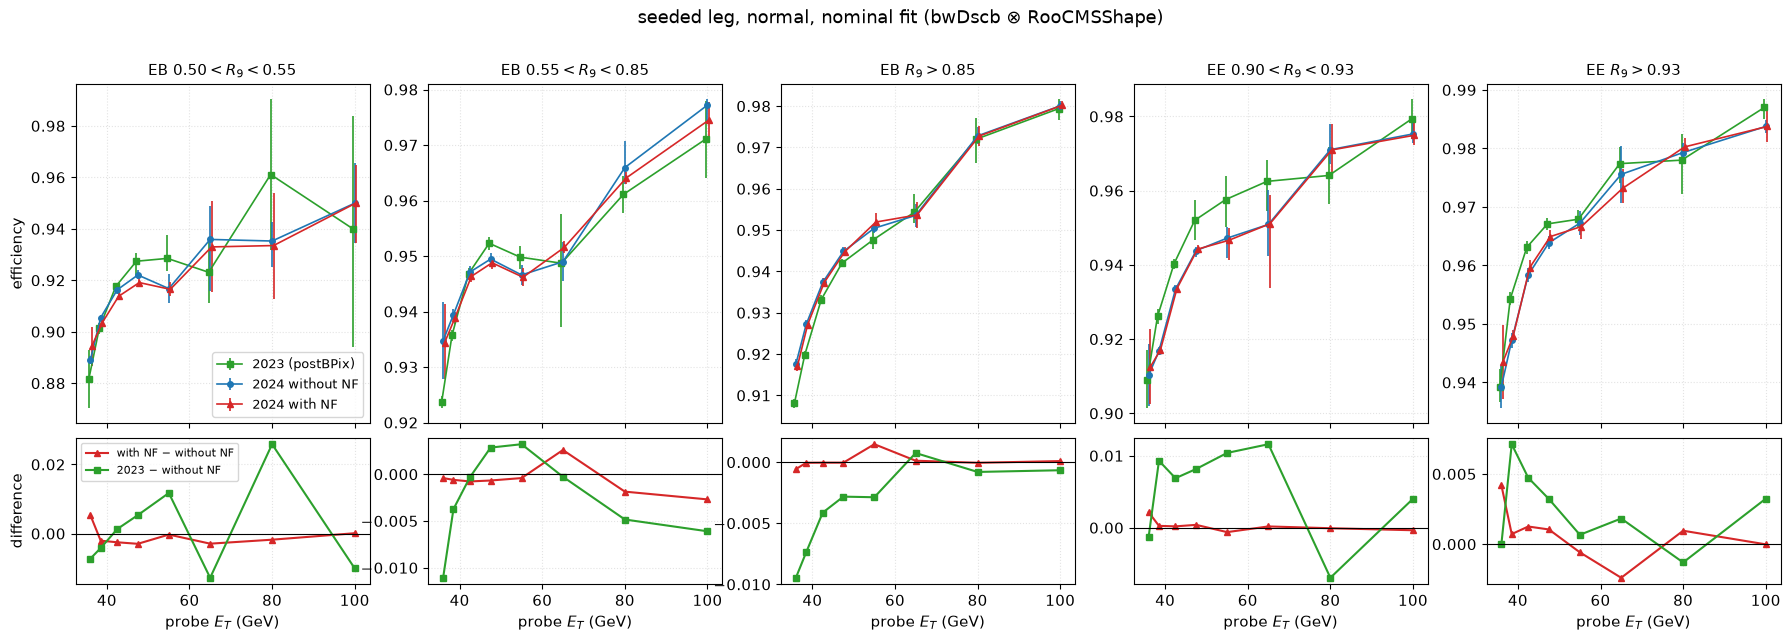

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/overview_normal_unseed.pdf


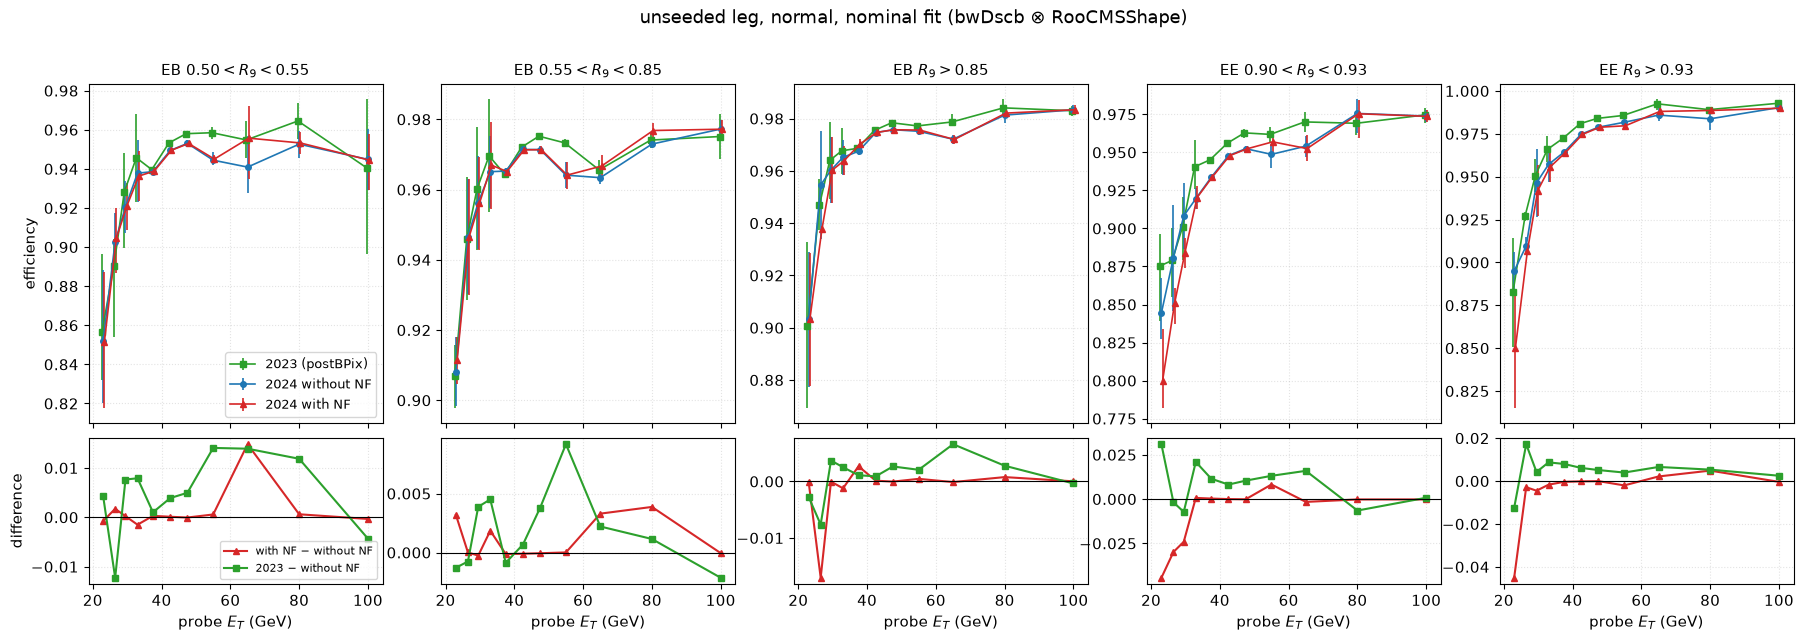

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/overview_fullPath_seed.pdf


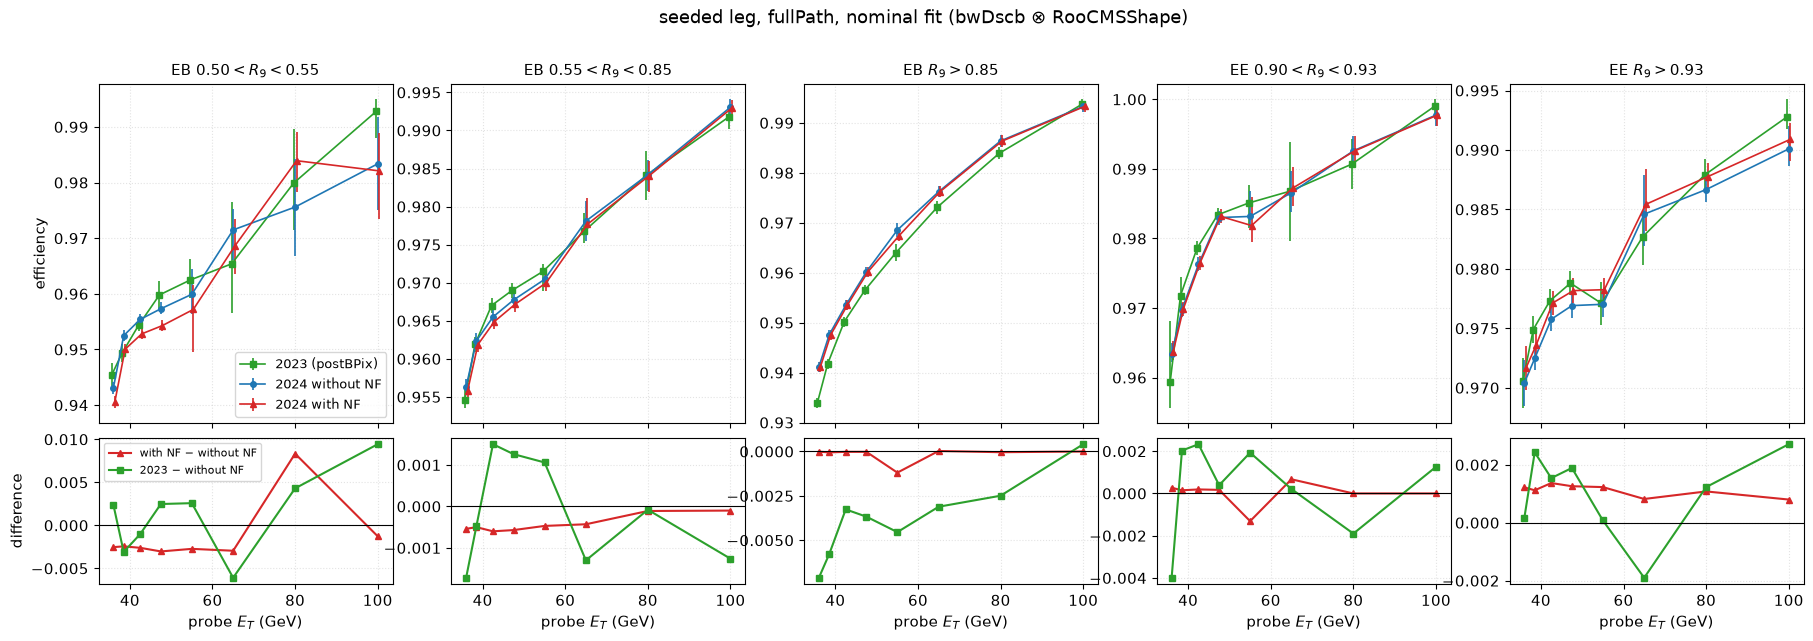

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/overview_fullPath_unseed.pdf


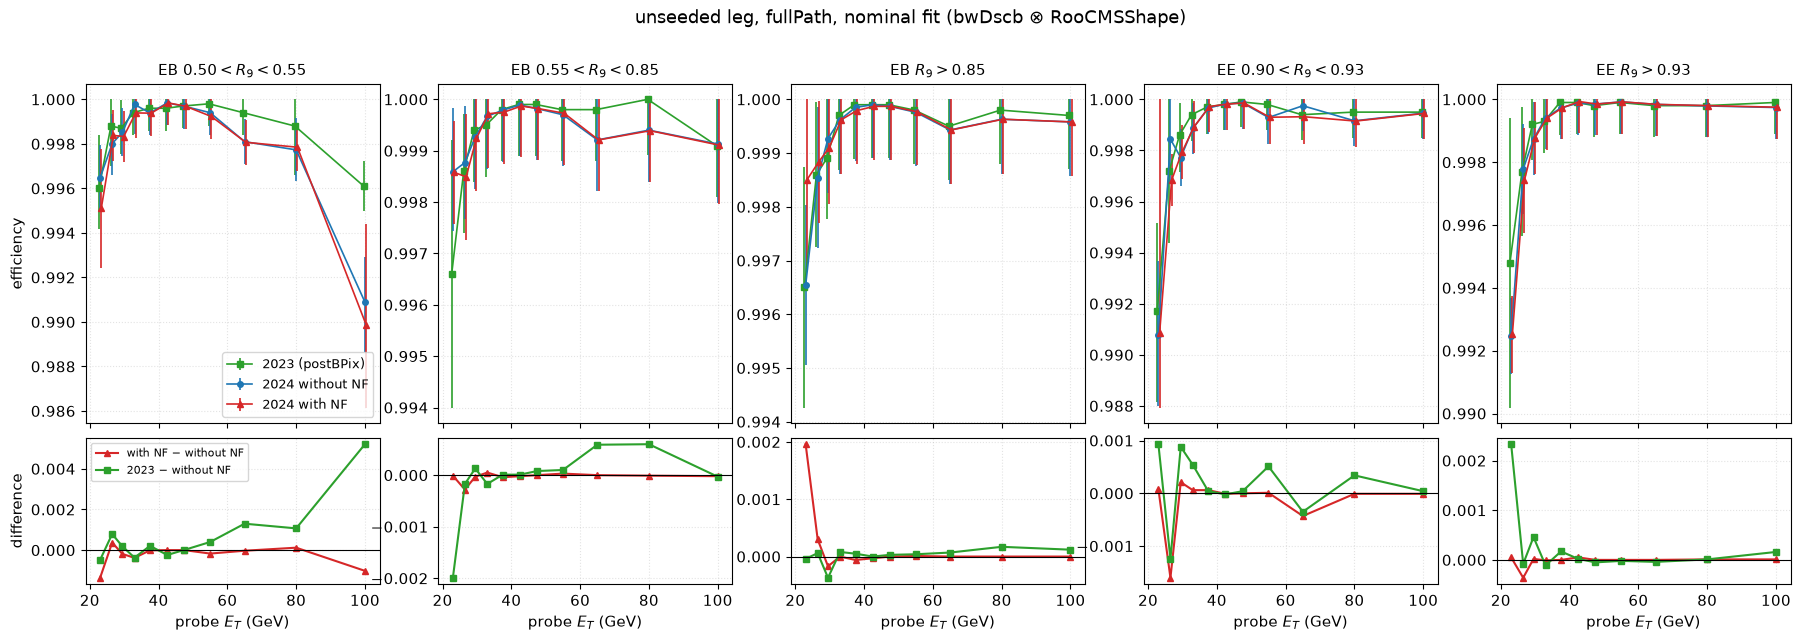

In [5]:
# [D2] One-page overview per leg
for st in SETS:
    for leg in LEGS:
        fig, ax = plt.subplots(2, 5, figsize=(22, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.3], 'hspace': 0.06})
        for j, cat in enumerate(CATS):
            g = W[(W.set == st) & (W.leg == leg) & (W.cat == cat)].sort_values('et_lo')
            g = g[g.et_lo > 0]   # drop the catch-all first bin, as in [D]
            x, xe = xpos(leg, g.et_lo.values, g.et_hi.values)
            for i, s in enumerate(('2023', 'repo', 'local')):
                ax[0, j].errorbar(x + (i - 1) * 0.35, g[f'eff_{s}'], yerr=[g[f'elo_{s}'], g[f'ehi_{s}']], color=SRC[s]['color'], marker=SRC[s]['marker'], ms=4, lw=1.2, label=SRC[s]['label'])
            ax[1, j].plot(x, g.d_local_repo, '-^', color=SRC['local']['color'], ms=4, label='with NF − without NF')
            ax[1, j].plot(x, g.d_2023_repo, '-s', color=SRC['2023']['color'], ms=4, label='2023 − without NF')
            ax[1, j].axhline(0, color='k', lw=0.8)
            ax[0, j].set_title(CAT_TEX[cat], fontsize=11)
            ax[1, j].set_xlabel(r'probe $E_T$ (GeV)')
        ax[0, 0].set_ylabel('efficiency'); ax[1, 0].set_ylabel('difference')
        ax[0, 0].legend(fontsize=9, loc='lower right'); ax[1, 0].legend(fontsize=8)
        fig.suptitle(f'{LEG_TEX[leg]} leg, {st}, nominal fit (bwDscb ⊗ RooCMSShape)', y=0.995)
        save(fig, PLOTS / 'eff' / f'overview_{st}_{leg}')
        plt.show()

## [D3] 2024 with NF only: five categories overlaid, one figure per leg
Plotting style of `/home/santanu/Documents/HLT_2024_IndiaCMS/src/make_overlays.py` (`plot_2024`): category colours and legend labels, `fmt="o"`, first bin dropped, overflow bin drawn at (90 + 125)/2, y range 0.5–1.02. Differences from it: values are `eff_local` of the normal set with the stat ⊕ syst errors of [B], and the header is the one of this notebook.

```mermaid
flowchart LR
    S[D3.1 STYLE: colours, labels, x cap] --> P[D3.2 SELECT: normal set, one leg, one category, first bin dropped]
    P --> Q[D3.3 DRAW: errorbar per category]
    Q --> V[D3.4 VALIDATE: point counts, range, values equal to W]
    V --> O[D3.5 SAVE: plots/eff/eff2024_withNF_<leg>.pdf/png]
```

seed: 40 points, eff 0.8944..0.9838, largest error bar 0.0206


/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff2024_withNF_seeded.pdf


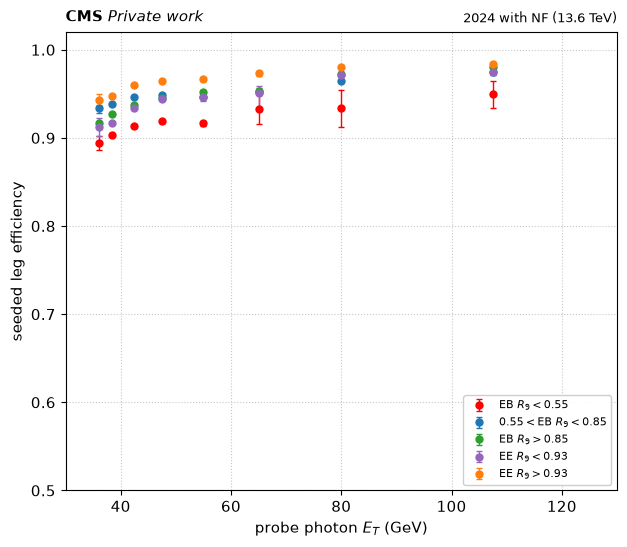

unseed: 55 points, eff 0.8001..0.9899, largest error bar 0.0362


/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/eff/eff2024_withNF_unseeded.pdf


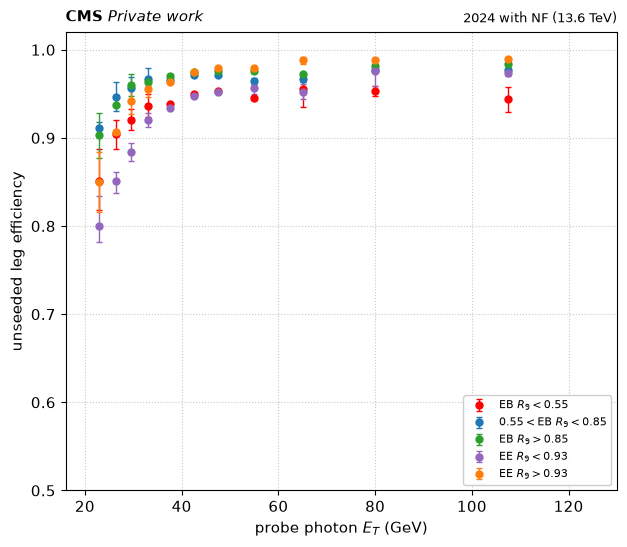

In [6]:
# [D3] 2024 with NF only: five categories overlaid, one figure per leg
# --- D3.1 STYLE (make_overlays.py:57-66)
PT_CAP_D3 = 120.0                                   # overflow bin right edge capped at PT_CAP_D3 + 5
CAT_STYLE_D3 = {'EB_R9_0p50to0p55': (r'EB $R_9 < 0.55$', 'red'),
                'EB_R9_0p55to0p85': (r'$0.55 < $EB $R_9 < 0.85$', 'tab:blue'),
                'EB_R9gt0p85':      (r'EB $R_9 > 0.85$', 'tab:green'),
                'EE_R9_0p90to0p93': (r'EE $R_9 < 0.93$', 'tab:purple'),
                'EE_R9gt0p93':      (r'EE $R_9 > 0.93$', 'tab:orange')}
MIN_PT_D3 = {'seed': 35.0, 'unseed': 21.0}          # lower edge of the first drawn bin
NPTS_D3   = {'seed': 8, 'unseed': 11}               # drawn bins per category (9 and 12 fitted, first dropped)

def overlay_with_nf(leg):
    fig, ax = plt.subplots(figsize=(6.4, 5.6))
    drawn = []
    for cat in CATS:
        # --- D3.2 SELECT
        g = W[(W.set == 'normal') & (W.leg == leg) & (W.cat == cat)].sort_values('et_lo')
        g = g[g.et_lo >= MIN_PT_D3[leg]]
        x = 0.5 * (g.et_lo.values + np.minimum(g.et_hi.values, PT_CAP_D3 + 5))
        # --- D3.3 DRAW   ax.errorbar: markers with asymmetric y errors, yerr = [lower, upper]
        lab, col = CAT_STYLE_D3[cat]
        ax.errorbar(x, g.eff_local, yerr=[g.elo_local, g.ehi_local], fmt='o', color=col, ms=5, lw=1.0, capsize=2, label=lab)
        drawn.append(g.assign(x=x))
    ax.set_xlim(max(15, MIN_PT_D3[leg] - 5), 130); ax.set_ylim(0.5, 1.02)
    ax.grid(True, ls=':', alpha=0.7)
    ax.set_xlabel(r'probe photon $E_T$ (GeV)', fontsize=11); ax.set_ylabel(f'{LEG_TEX[leg]} leg efficiency', fontsize=11)
    ax.legend(loc='lower right', fontsize=8, framealpha=0.95)
    label(ax, '2024 with NF (13.6 TeV)')
    # --- D3.4 VALIDATE
    d = pd.concat(drawn)
    assert d.groupby('cat').size().eq(NPTS_D3[leg]).all() and d.cat.nunique() == 5, d.groupby('cat').size()
    assert d.eff_local.between(0.5, 1.0).all(), 'a point lies outside the drawn y range'
    assert (d.eff_local - d.elo_local >= 0.5).all(), 'an error bar is clipped by the y range'
    src = E[(E.src == 'local') & (E.set == 'normal') & (E.leg == leg)].set_index(['cat', 'et_lo'])
    assert np.allclose(d.eff_local.values, src.loc[list(zip(d.cat, d.et_lo)), 'eff'].values), 'W differs from the egammaEffi.txt values'
    assert d.x.max() == 107.5 and d.x.min() == {'seed': 36.0, 'unseed': 23.0}[leg]
    print(f'{leg}: {len(d)} points, eff {d.eff_local.min():.4f}..{d.eff_local.max():.4f}, largest error bar {max(d.elo_local.max(), d.ehi_local.max()):.4f}')
    # --- D3.5 SAVE
    fig.tight_layout()
    save(fig, PLOTS / 'eff' / f'eff2024_withNF_{LEG_TEX[leg]}')
    plt.show()

for leg in LEGS:
    overlay_with_nf(leg)


## [E] Difference heatmaps
Rows = category, columns = pT bin. Left: local − repo (absolute). Right: the same divided by the quadrature sum of the two fit uncertainties. `TwoSlopeNorm` centres the colour scale on 0.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/diff/heat_local_minus_repo_normal.pdf


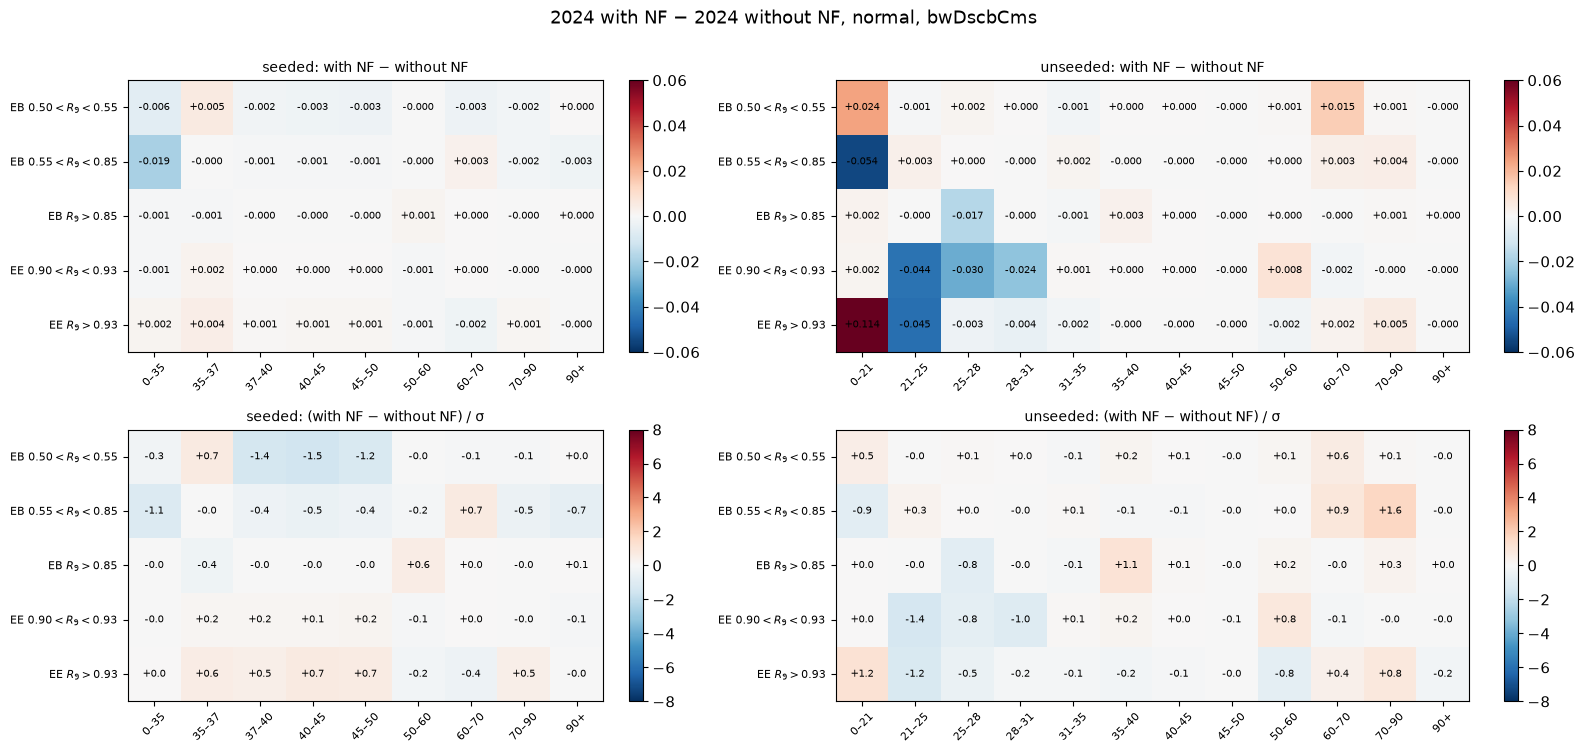

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/diff/heat_local_minus_repo_fullPath.pdf


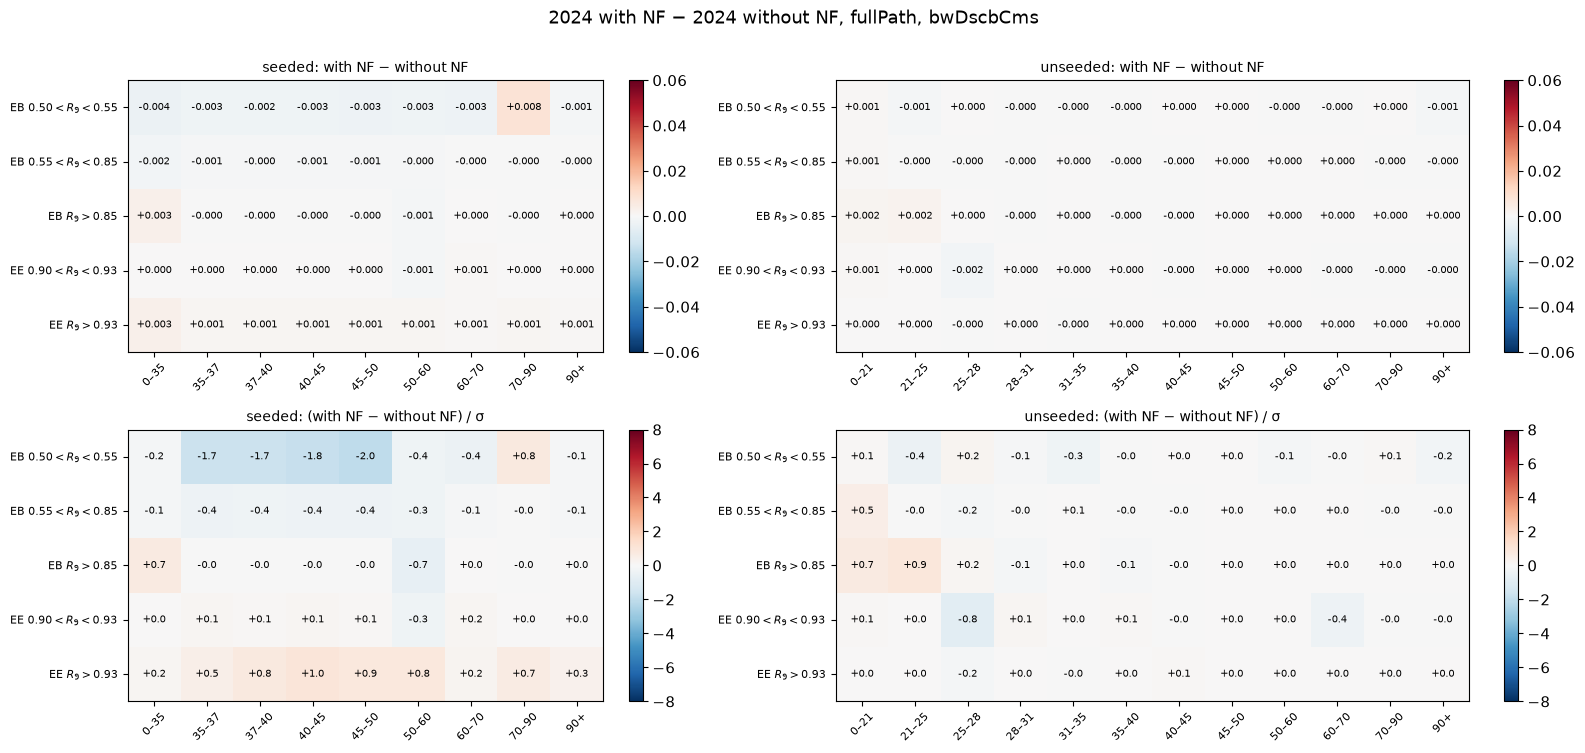

In [7]:
# [E] Difference heatmaps
def heat(st):
    fig, ax = plt.subplots(2, 2, figsize=(16, 7.5), gridspec_kw={'width_ratios': [9, 12]})
    for i, leg in enumerate(LEGS):
        g = W[(W.set == st) & (W.leg == leg)]
        edges = sorted(set(zip(g.et_lo, g.et_hi)))
        for j, (col, title, lim) in enumerate((('d_local_repo', 'with NF − without NF', 0.06), ('pull_local_repo', '(with NF − without NF) / σ', 8))):
            M = np.array([[g[(g.cat == c) & (g.et_lo == lo)][col].iloc[0] for lo, hi in edges] for c in CATS])
            a = ax[j, i]
            im = a.imshow(M, cmap='RdBu_r', norm=TwoSlopeNorm(0, -lim, lim), aspect='auto')
            for (r_, c_), v in np.ndenumerate(M):
                a.text(c_, r_, f'{v:+.3f}' if j == 0 else f'{v:+.1f}', ha='center', va='center', fontsize=7)
            a.set_yticks(range(5)); a.set_yticklabels([CAT_TEX[c] for c in CATS], fontsize=8)
            a.set_xticks(range(len(edges))); a.set_xticklabels([f'{lo:g}–{hi:g}' if hi < 1e5 else f'{lo:g}+' for lo, hi in edges], rotation=45, fontsize=8)
            a.set_title(f'{LEG_TEX[leg]}: {title}', fontsize=10); a.grid(False)
            fig.colorbar(im, ax=a, fraction=0.04)
    fig.suptitle(f'2024 with NF − 2024 without NF, {st}, bwDscbCms', y=1.0)
    fig.tight_layout()
    save(fig, PLOTS / 'diff' / f'heat_local_minus_repo_{st}')
    plt.show()

for st in SETS:
    heat(st)

## [F] Load maps and cell counts
The 25 × 16 maps (R9 × |eta|) and the per-cell probe counts from notebook 01. `npz` keys are `counts__<leg>__<set>__<cat>` with shape [pT bin, fail/pass, cell].

In [8]:
# [F] Load maps and cell counts
Z = np.load(ROOT_DIR / 'data' / 'cell_counts.npz')
R9E, ETAE = Z['r9_edges'], Z['eta_edges']
MO, MN = Z['map_old'], Z['map_new']
NX, NY = MO.shape
val = json.loads((ROOT_DIR / 'data' / 'scan_validation.json').read_text())
print('map shape', MO.shape, '| scan entries', val['entries'], '| lookup mismatches', val['mismatch_old'], val['mismatch_new'])
C = {}
for st in SETS:
    for leg in LEGS:
        for cat in CATS:
            k = f'{leg}__{st}__{cat}'
            pt = Z['pt__' + k]; C[(st, leg, cat)] = dict(n=Z['counts__' + k][:len(pt) - 1].reshape(len(pt) - 1, 2, NX, NY), pt=pt)
r9lab  = [f'{a:g}–{b:g}' for a, b in zip(R9E[:-1], R9E[1:])]
etalab = [f'{a:g}–{b:g}' for a, b in zip(ETAE[:-1], ETAE[1:])]
print('cells: old==1:', int((MO == 1).sum()), ' new==0:', int((MN == 0).sum()))

map shape (25, 16) | scan entries {'seed': 159861517, 'unseed': 159861517} | lookup mismatches {'seed': 0, 'unseed': 0} {'seed': 0, 'unseed': 0}
cells: old==1: 118  new==0: 4


## [G] Map comparison plots
Plotted in **bin-index space** (the R9 bins run 0–0.5, then 0.05/0.02/0.01 wide, so a linear axis would hide them); tick labels give the edges. Panels: old, new, new/old, new − old. Cells annotated with values.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/maps/map_old_map_2024_repo.pdf


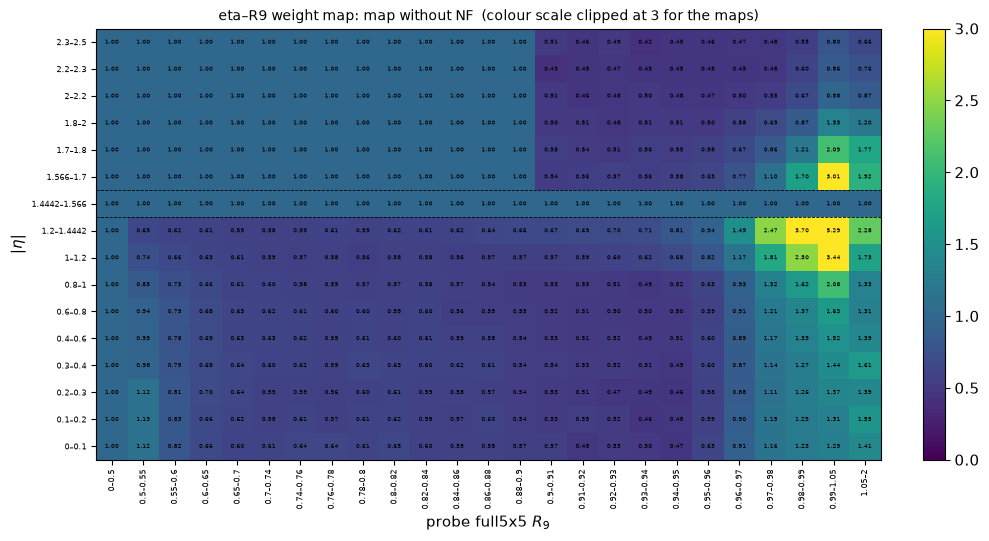

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/maps/map_new_map_2024_local.pdf


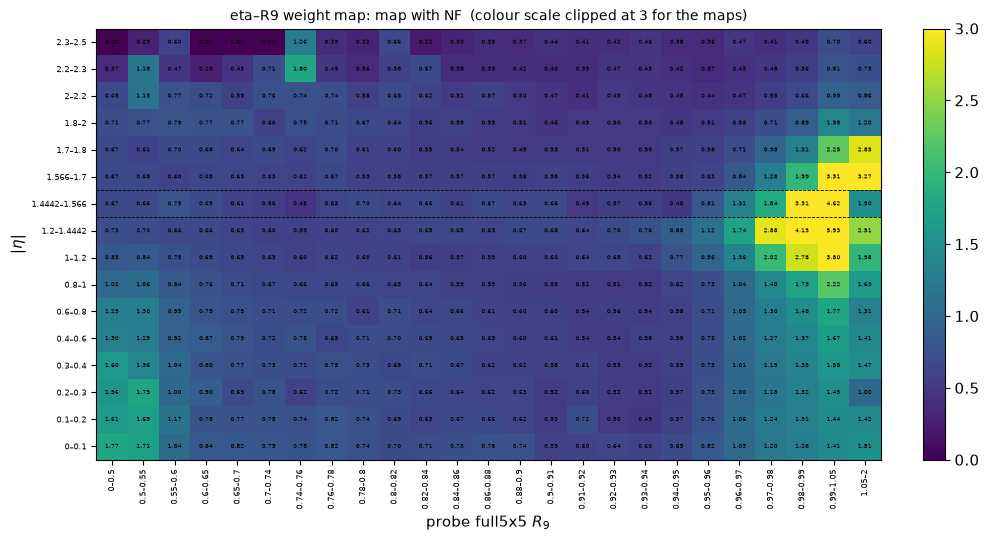

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/maps/map_new_old.pdf


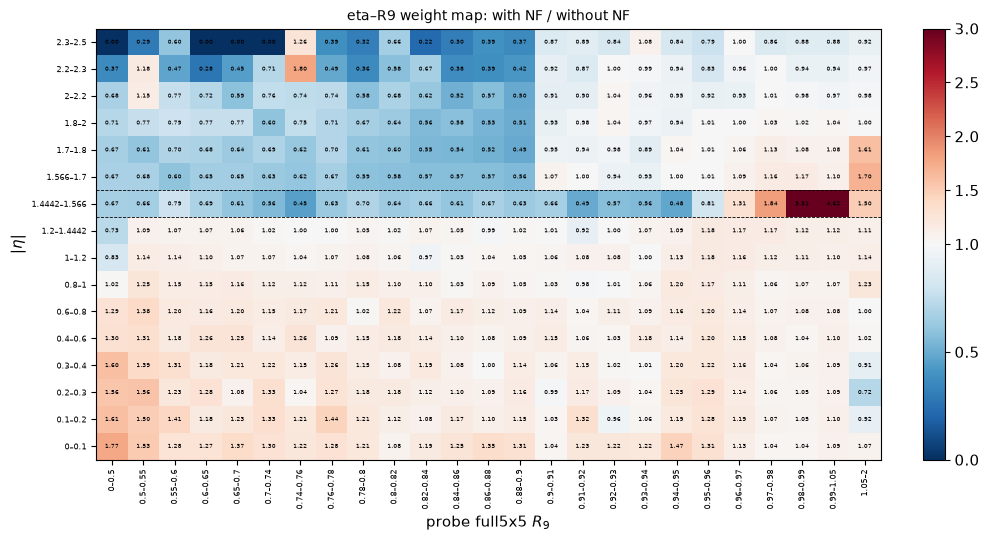

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/maps/map_new_old_diff.pdf


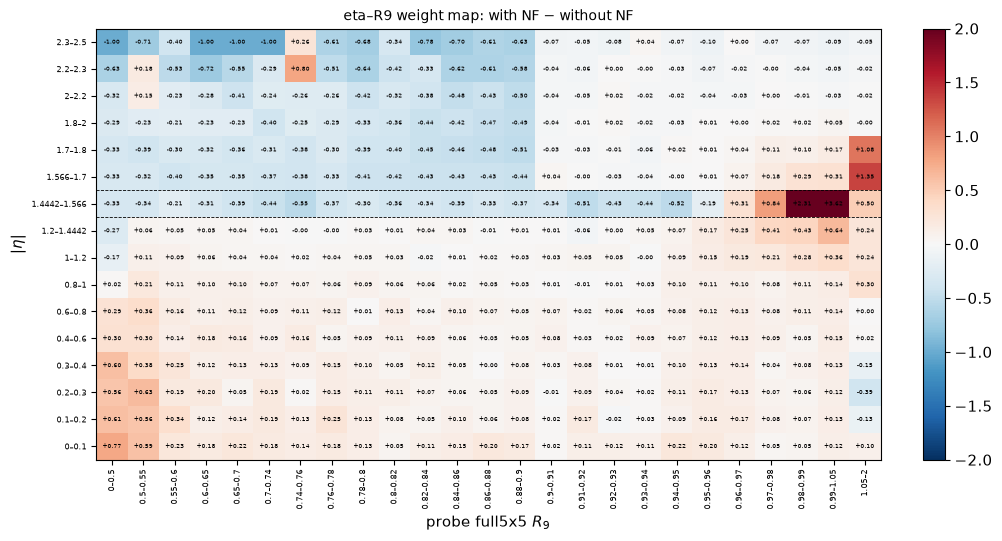

In [9]:
# [G] Map comparison plots
def grid_axes(a):
    a.set_xticks(range(NX)); a.set_xticklabels(r9lab, rotation=90, fontsize=6)
    a.set_yticks(range(NY)); a.set_yticklabels(etalab, fontsize=6)
    a.set_xlabel(r'probe full5x5 $R_9$'); a.set_ylabel(r'$|\eta|$'); a.grid(False)
    a.axhline(8.5, color='k', lw=0.6, ls='--'); a.axhline(9.5, color='k', lw=0.6, ls='--')   # EB/EE gap rows (1.4442–1.566)

def annotate(a, M, fmt, size=4.6):
    for (i, j), v in np.ndenumerate(M):
        a.text(i, j, fmt.format(v), ha='center', va='center', fontsize=size)

with np.errstate(divide='ignore', invalid='ignore'):
    RATIO = np.where(MO > 0, MN / MO, np.nan)
DIFF = MN - MO
panels = [('map without NF', 'map_old_map_2024_repo', MO, 'viridis', None, '{:.2f}'),
          ('map with NF', 'map_new_map_2024_local', MN, 'viridis', None, '{:.2f}'),
          ('with NF / without NF', 'map_new_old', RATIO, 'RdBu_r', TwoSlopeNorm(1, 0, 3), '{:.2f}'),
          ('with NF − without NF', 'map_new_old_diff', DIFF, 'RdBu_r', TwoSlopeNorm(0, -2, 2), '{:+.2f}')]
vmax = float(max(MO.max(), MN.max()))
for name, fname, M, cmap, norm, fmt in panels:
    fig, a = plt.subplots(figsize=(11, 5.6))
    kw = dict(norm=norm) if norm else dict(vmin=0, vmax=min(vmax, 3))
    im = a.imshow(M.T, origin='lower', cmap=cmap, aspect='auto', **kw)
    annotate(a, M, fmt); grid_axes(a); fig.colorbar(im, ax=a, fraction=0.03)
    a.set_title(f'eta–R9 weight map: {name}  (colour scale clipped at 3 for the maps)' if norm is None else f'eta–R9 weight map: {name}', fontsize=10)
    save(fig, PLOTS / 'maps' / fname)
    plt.show()

## [G2] Map slices
Map value vs R9 bin, one panel per |eta| row, old vs new. Shaded: the R9 windows of the analysis categories (EB rows: 0.50–0.55, 0.55–0.85, > 0.85; EE rows: 0.90–0.93, > 0.93).

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/maps/map_slices_vs_r9.pdf


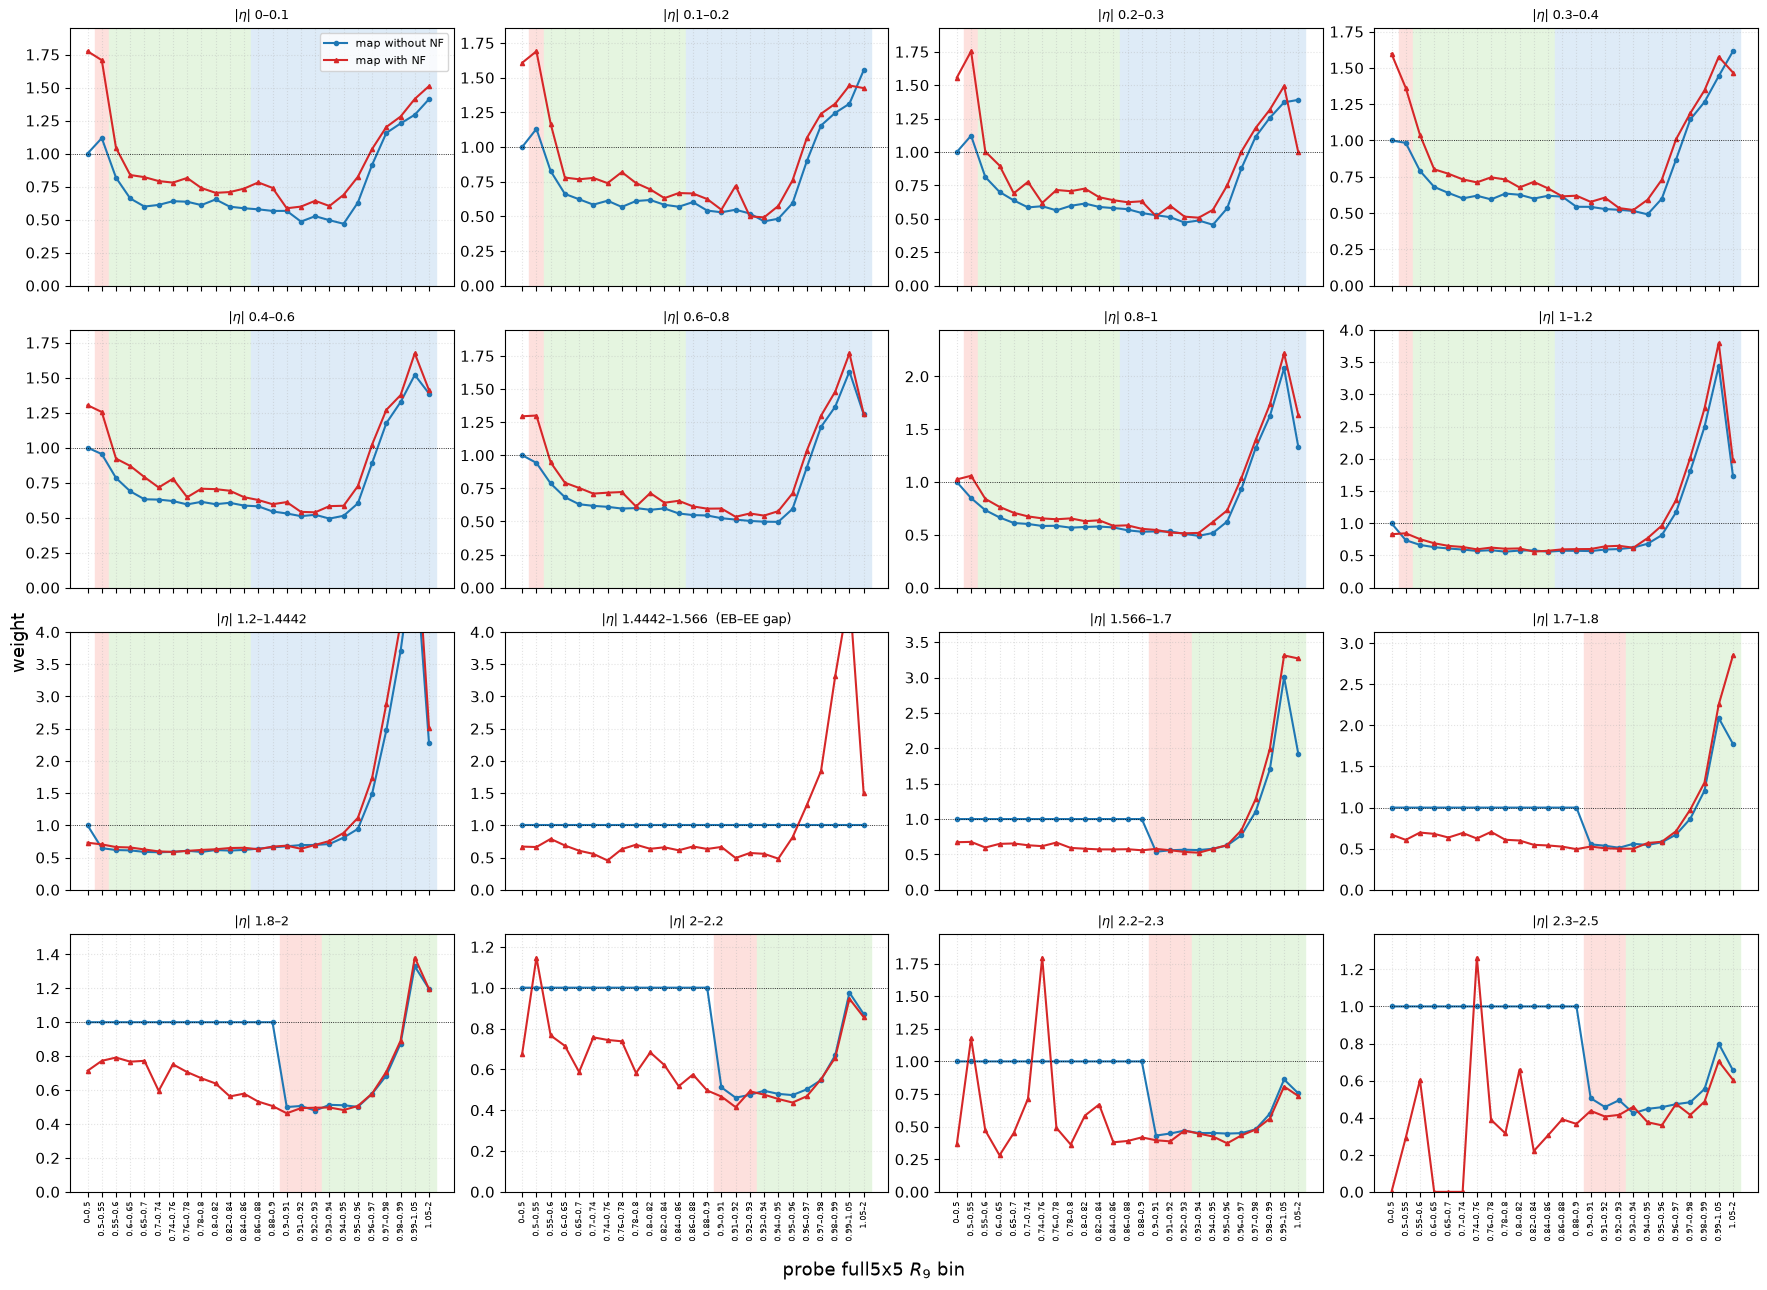

In [10]:
# [G2] Map slices
CAT_R9 = {'EB': [(0.50, 0.55), (0.55, 0.85), (0.85, 2.0)], 'EE': [(0.90, 0.93), (0.93, 2.0)]}
def r9_idx(v):
    return int(np.searchsorted(R9E, v - 1e-9))
fig, axs = plt.subplots(4, 4, figsize=(18, 13), sharex=True)
for j, a in enumerate(axs.flat):
    reg = 'EB' if ETAE[j + 1] <= 1.4442 + 1e-6 else ('EE' if ETAE[j] >= 1.566 - 1e-6 else None)
    if reg:
        for k, (lo, hi) in enumerate(CAT_R9[reg]):
            a.axvspan(r9_idx(lo) - 0.5, r9_idx(hi) - 0.5, color=['#fde0dd', '#e5f5e0', '#deebf7'][k], zorder=0)
    a.plot(range(NX), MO[:, j], '-o', ms=3, color=SRC['repo']['color'], label='map without NF')
    a.plot(range(NX), MN[:, j], '-^', ms=3, color=SRC['local']['color'], label='map with NF')
    a.axhline(1, color='k', lw=0.6, ls=':')
    a.set_title(rf'$|\eta|$ {etalab[j]}' + ('' if reg else '  (EB–EE gap)'), fontsize=9)
    a.set_ylim(0, min(4, max(MO[:, j].max(), MN[:, j].max()) * 1.1))
for a in axs[-1]:
    a.set_xticks(range(NX)); a.set_xticklabels(r9lab, rotation=90, fontsize=6)
axs[0, 0].legend(fontsize=8)
fig.supxlabel(r'probe full5x5 $R_9$ bin'); fig.supylabel('weight')
fig.tight_layout()
save(fig, PLOTS / 'maps' / 'map_slices_vs_r9')
plt.show()

## [H] Probe occupancy
Where the selected probes sit on the map grid, per category (normal set, pass + fail, all pT bins). `LogNorm` because occupancy spans orders of magnitude. Cells with an old-map value of exactly 1 (hatched `//`) and new-map value 0 (hatched `xx`) are marked.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/occupancy_seed.pdf


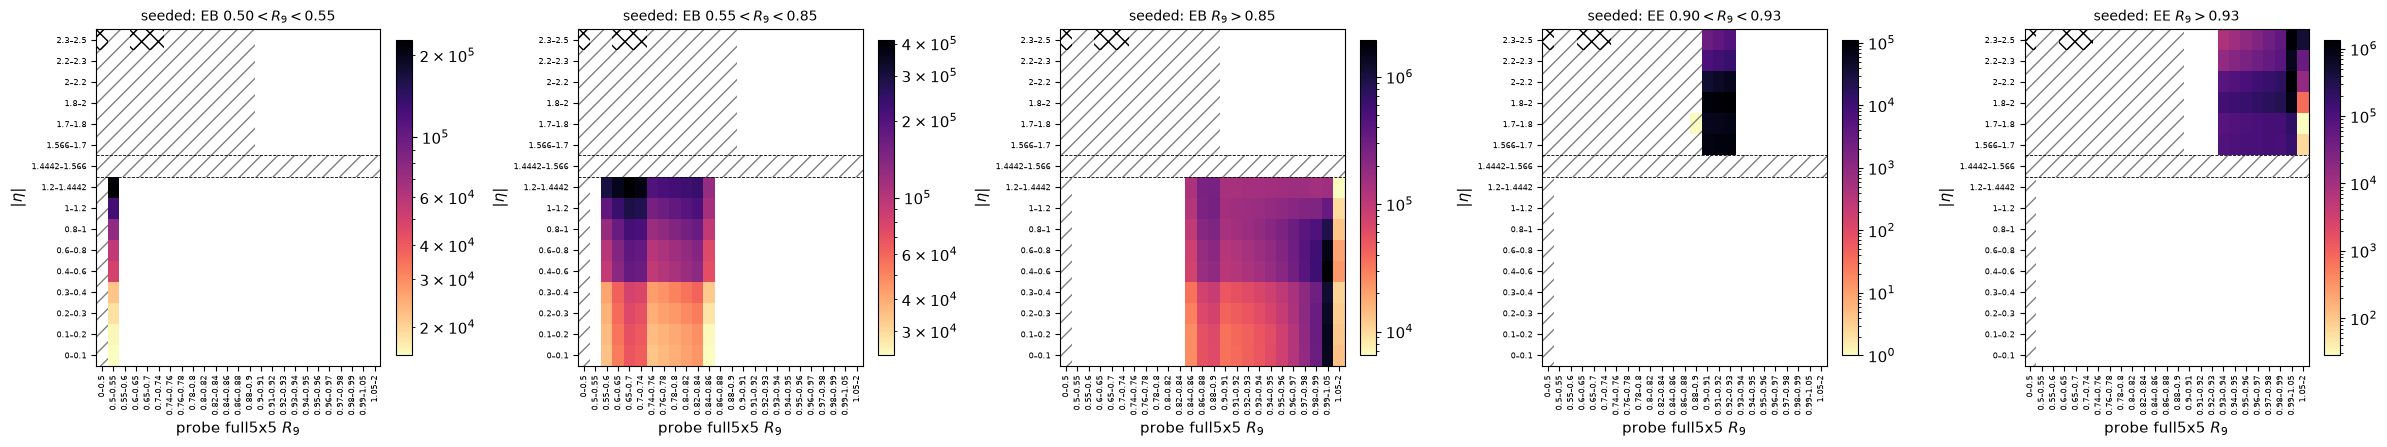

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/occupancy_unseed.pdf


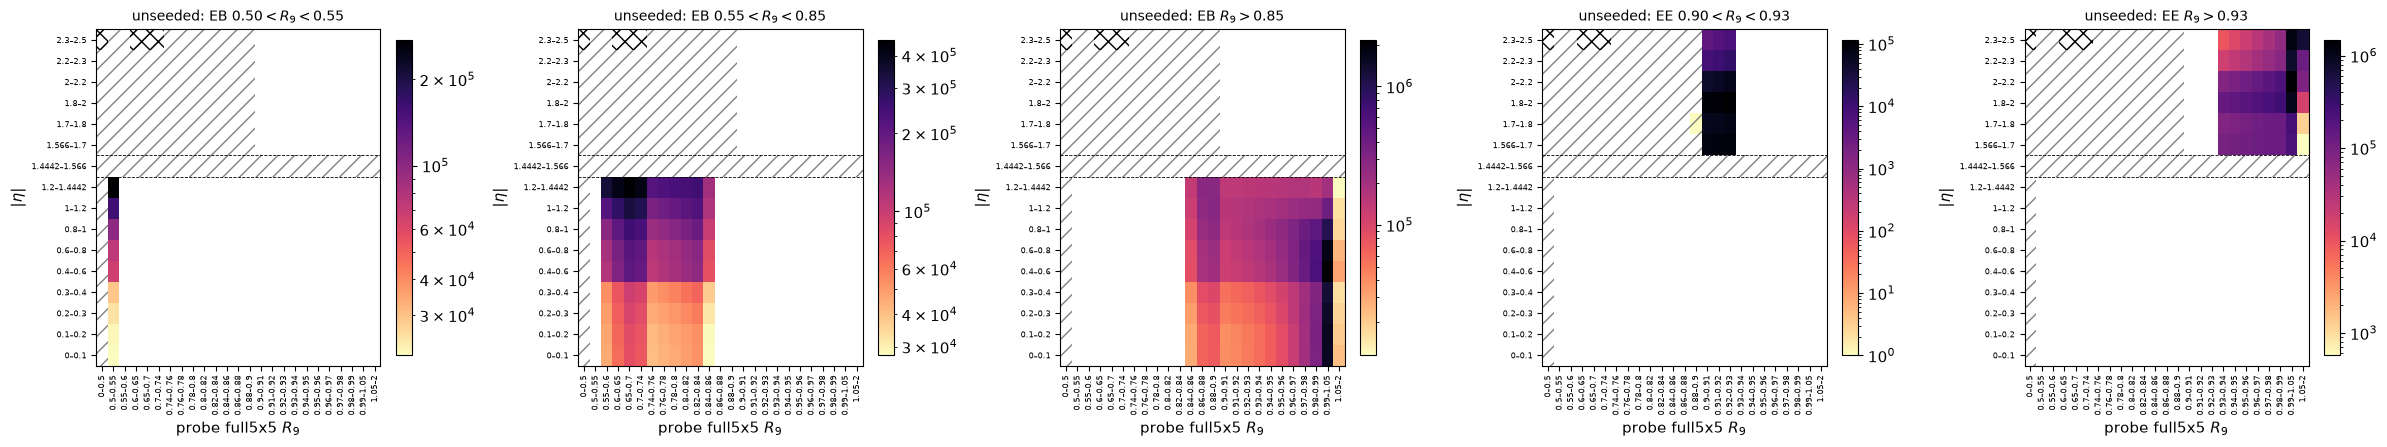

,leg,cat,probes,cells_used,frac_old_eq_1,frac_new_eq_0
0,seed,EB_R9_0p50to0p55,610203,9,0.0,0.0
1,seed,EB_R9_0p55to0p85,10623354,90,0.0,0.0
2,seed,EB_R9gt0p85,27285255,126,0.0,0.0
3,seed,EE_R9_0p90to0p93,920092,19,0.0,0.0
4,seed,EE_R9gt0p93,8643484,48,0.0,0.0
5,unseed,EB_R9_0p50to0p55,773578,9,0.0,0.0
6,unseed,EB_R9_0p55to0p85,12086789,90,0.0,0.0
7,unseed,EB_R9gt0p85,29556173,126,0.0,0.0
8,unseed,EE_R9_0p90to0p93,978124,19,0.0,0.0
9,unseed,EE_R9gt0p93,9468312,48,0.0,0.0


In [11]:
# [H] Probe occupancy
OCC = {}
for leg in LEGS:
    fig, axs = plt.subplots(1, 5, figsize=(24, 4.6))
    for a, cat in zip(axs, CATS):
        occ = C[('normal', leg, cat)]['n'].sum(axis=(0, 1)).astype(float)
        OCC[(leg, cat)] = occ
        im = a.imshow(np.where(occ > 0, occ, np.nan).T, origin='lower', aspect='auto', cmap='magma_r', norm=LogNorm())
        for (i, j), v in np.ndenumerate(MO):
            if v == 1: a.add_patch(plt.Rectangle((i - .5, j - .5), 1, 1, fill=False, hatch='//', lw=0, color='0.5'))
            if MN[i, j] == 0: a.add_patch(plt.Rectangle((i - .5, j - .5), 1, 1, fill=False, hatch='xx', lw=0, color='k'))
        grid_axes(a); a.set_title(f'{LEG_TEX[leg]}: {CAT_TEX[cat]}', fontsize=10)
        fig.colorbar(im, ax=a, fraction=0.05)
    fig.tight_layout()
    save(fig, PLOTS / 'why' / f'occupancy_{leg}')
    plt.show()
occ_summary = []
for (leg, cat), occ in OCC.items():
    tot = occ.sum()
    occ_summary.append(dict(leg=leg, cat=cat, probes=int(tot), cells_used=int((occ > 0).sum()),
                            frac_old_eq_1=occ[MO == 1].sum() / tot, frac_new_eq_0=occ[MN == 0].sum() / tot))
occ_summary = pd.DataFrame(occ_summary); occ_summary.round(5)

## [I] Counting efficiency, old vs new map
For each fitter bin, weighted pass and fail yields under each map: P = Σ N_pass(cell)·w(cell), F likewise; ε_count = P / (P + F). No background subtraction — this is **not** the fitted efficiency; its old→new change shows how much the weights alone move the pass/fail balance. Also the mean weight of passing and failing probes.

In [12]:
# [I] Counting efficiency, old vs new map
rows = []
for (st, leg, cat), d in C.items():
    n, pt = d['n'], d['pt']
    for ib in range(len(pt) - 1):
        nf, np_ = n[ib, 0], n[ib, 1]
        r = dict(set=st, leg=leg, cat=cat, et_lo=pt[ib], et_hi=pt[ib + 1], N_pass=int(np_.sum()), N_fail=int(nf.sum()))
        r['eff_count_raw'] = np_.sum() / (np_.sum() + nf.sum())
        for tag, M in (('old', MO), ('new', MN)):
            P, F = (np_ * M).sum(), (nf * M).sum()
            P2, F2 = (np_ * M**2).sum(), (nf * M**2).sum()
            r[f'eff_count_{tag}'] = P / (P + F)
            r[f'wpass_{tag}'] = P / np_.sum(); r[f'wfail_{tag}'] = F / nf.sum()
            r[f'neff_{tag}'] = (P + F) ** 2 / (P2 + F2)
            r[f'neff_fail_{tag}'] = F ** 2 / F2
        rows.append(r)
K = pd.DataFrame(rows)
K['d_count'] = K.eff_count_new - K.eff_count_old
K = K.merge(W[['set'] + KEY + ['eff_repo', 'eff_local', 'd_local_repo', 'pull_local_repo', 'err_repo', 'err_local']], on=['set', 'leg', 'cat', 'et_lo', 'et_hi'], validate='one_to_one')
assert len(K) == 210 and K[['eff_count_old', 'eff_count_new']].stack().between(0, 1).all()
K.to_csv(ROOT_DIR / 'data' / 'counting_vs_fit.csv', index=False, float_format='%.6g')
print(ROOT_DIR / 'data' / 'counting_vs_fit.csv')
print(K.groupby('set')[['d_count', 'd_local_repo']].agg(['mean', lambda s: s.abs().max()]).round(5))

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/data/counting_vs_fit.csv
          d_count            d_local_repo           
             mean <lambda_0>         mean <lambda_0>
set                                                 
fullPath -0.00017    0.00432     -0.00002    0.00833
normal   -0.00010    0.00480     -0.00067    0.11388


## [J] Fit shift vs counting shift
Left: per bin, fitted shift (local − repo) against the counting shift (new − old map). If the weights alone drove the fitted change, points would sit on the diagonal. Right: per category, both shifts vs pT (connected).

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/fit_vs_count_scatter_normal.pdf


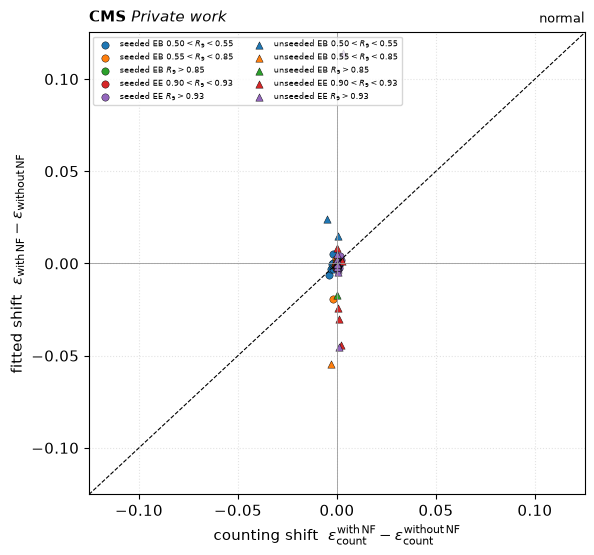

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/fit_vs_count_vs_pt_normal_seed.pdf


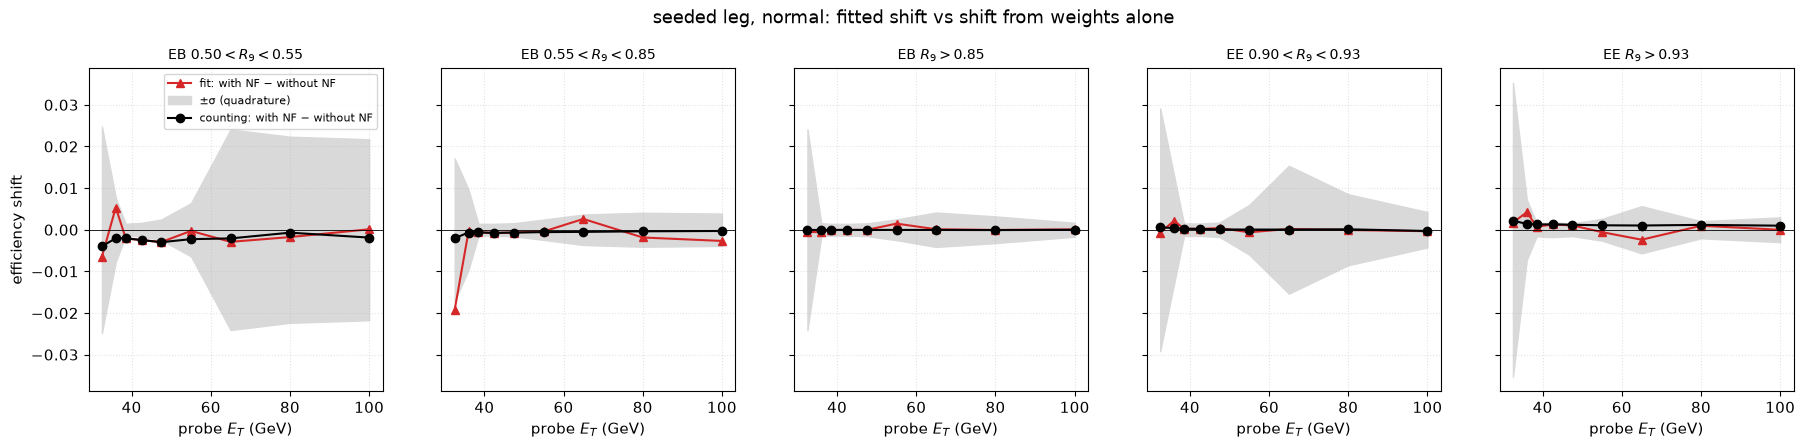

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/fit_vs_count_vs_pt_normal_unseed.pdf


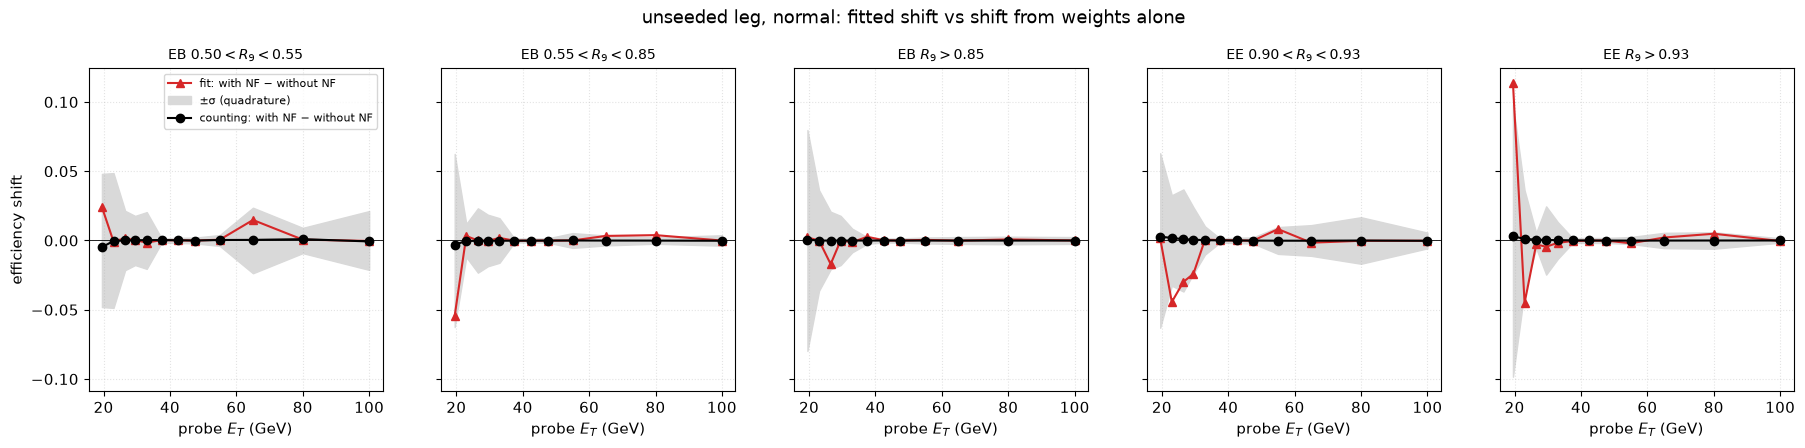

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/fit_vs_count_scatter_fullPath.pdf


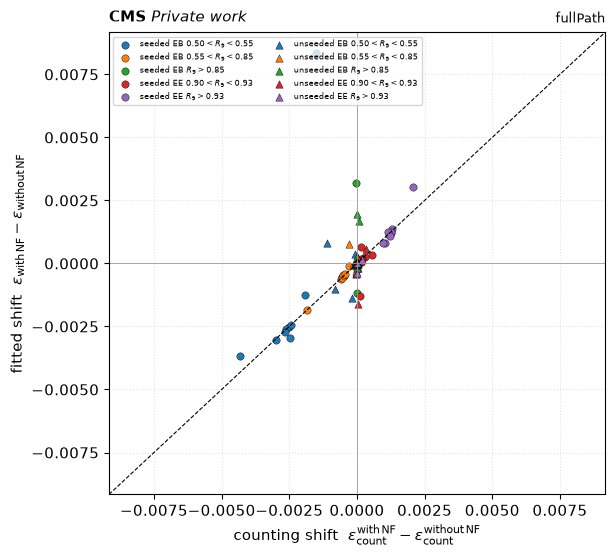

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/fit_vs_count_vs_pt_fullPath_seed.pdf


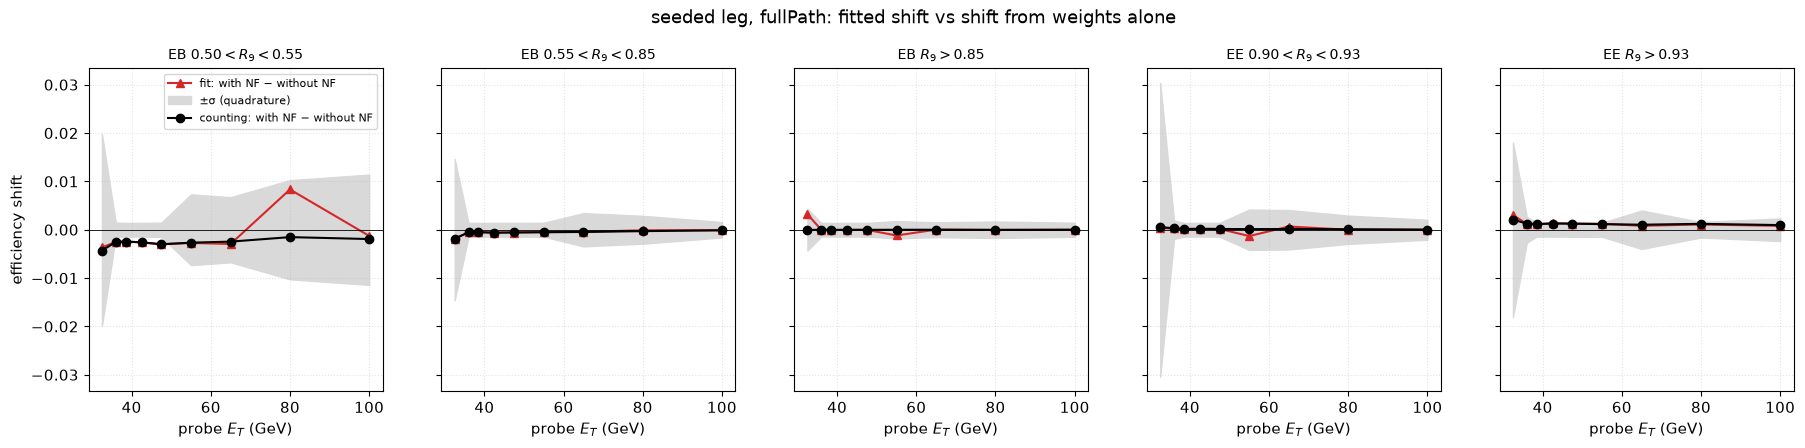

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/fit_vs_count_vs_pt_fullPath_unseed.pdf


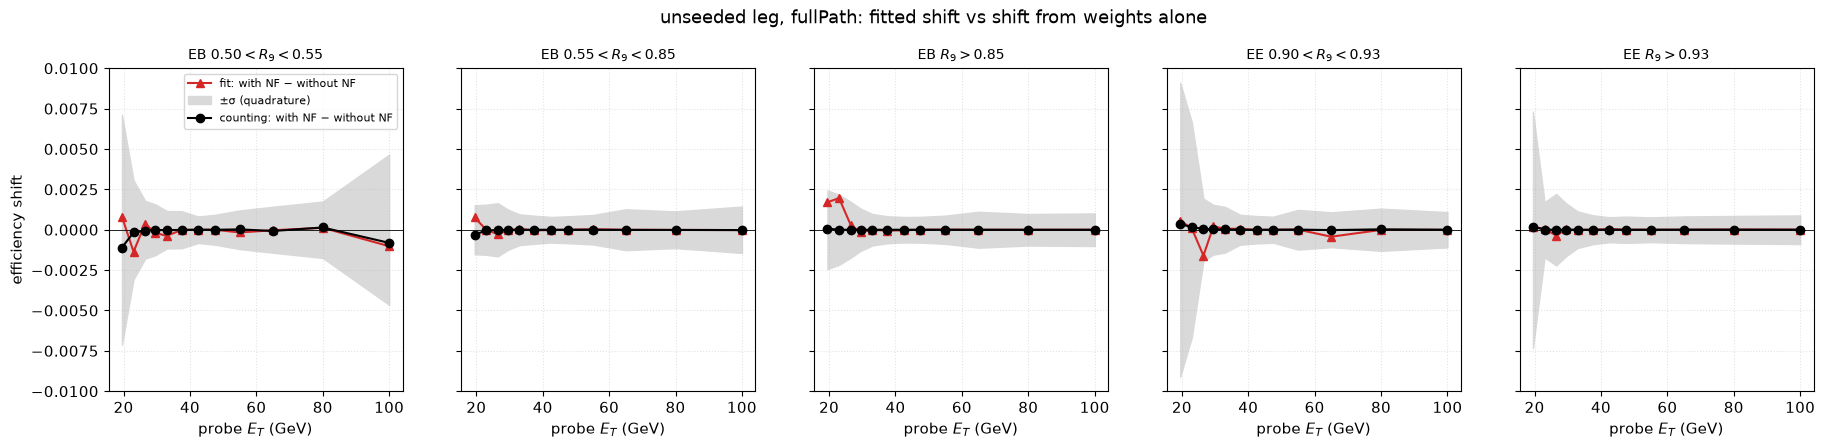

In [13]:
# [J] Fit shift vs counting shift
for st in SETS:
    k = K[K.set == st]
    fig, a = plt.subplots(figsize=(6.4, 6))
    for leg, mk in (('seed', 'o'), ('unseed', '^')):
        for cat, col in zip(CATS, plt.cm.tab10.colors):
            g = k[(k.leg == leg) & (k.cat == cat)]
            a.scatter(g.d_count, g.d_local_repo, marker=mk, color=col, s=28, label=f'{LEG_TEX[leg]} {CAT_TEX[cat]}', edgecolor='k', lw=0.3)
    lim = max(k.d_local_repo.abs().max(), k.d_count.abs().max()) * 1.1
    a.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8); a.axhline(0, color='0.6', lw=0.6); a.axvline(0, color='0.6', lw=0.6)
    a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
    a.set_xlabel(r'counting shift  $\varepsilon^{\rm with\,NF}_{\rm count}-\varepsilon^{\rm without\,NF}_{\rm count}$')
    a.set_ylabel(r'fitted shift  $\varepsilon_{\rm with\,NF}-\varepsilon_{\rm without\,NF}$')
    a.legend(fontsize=6, ncol=2, loc='upper left'); label(a, st)
    save(fig, PLOTS / 'why' / f'fit_vs_count_scatter_{st}')
    plt.show()

    for leg in LEGS:
        fig, axs = plt.subplots(1, 5, figsize=(22, 4.2), sharey=True)
        for a, cat in zip(axs, CATS):
            g = k[(k.leg == leg) & (k.cat == cat)].sort_values('et_lo')
            x, _ = xpos(leg, g.et_lo.values, g.et_hi.values)
            a.plot(x, g.d_local_repo, '-^', color=SRC['local']['color'], label='fit: with NF − without NF')
            a.fill_between(x, -np.hypot(g.err_repo, g.err_local), np.hypot(g.err_repo, g.err_local), color='0.85', label='±σ (quadrature)')
            a.plot(x, g.d_count, '-o', color='k', label='counting: with NF − without NF')
            a.axhline(0, color='k', lw=0.6); a.set_title(CAT_TEX[cat], fontsize=10); a.set_xlabel(r'probe $E_T$ (GeV)')
        axs[0].set_ylabel('efficiency shift'); axs[0].legend(fontsize=8)
        fig.suptitle(f'{LEG_TEX[leg]} leg, {st}: fitted shift vs shift from weights alone', y=1.02)
        save(fig, PLOTS / 'why' / f'fit_vs_count_vs_pt_{st}_{leg}')
        plt.show()

## [J2] Mean weight of passing vs failing probes
The counting efficiency only moves if the map changes the mean weight of passing and failing probes differently: ε_new/ε_old depends on ⟨w⟩_pass/⟨w⟩_fail. Plotted: ⟨w⟩_pass/⟨w⟩_fail for each map vs pT.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/wpass_over_wfail_seed.pdf


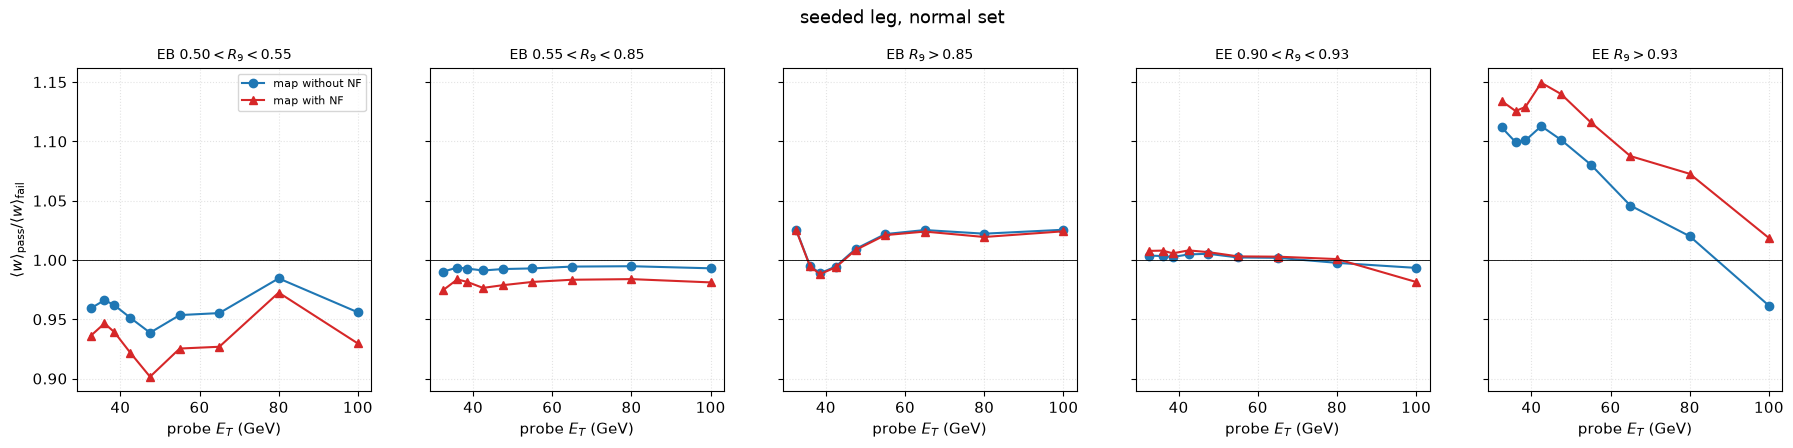

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/wpass_over_wfail_unseed.pdf


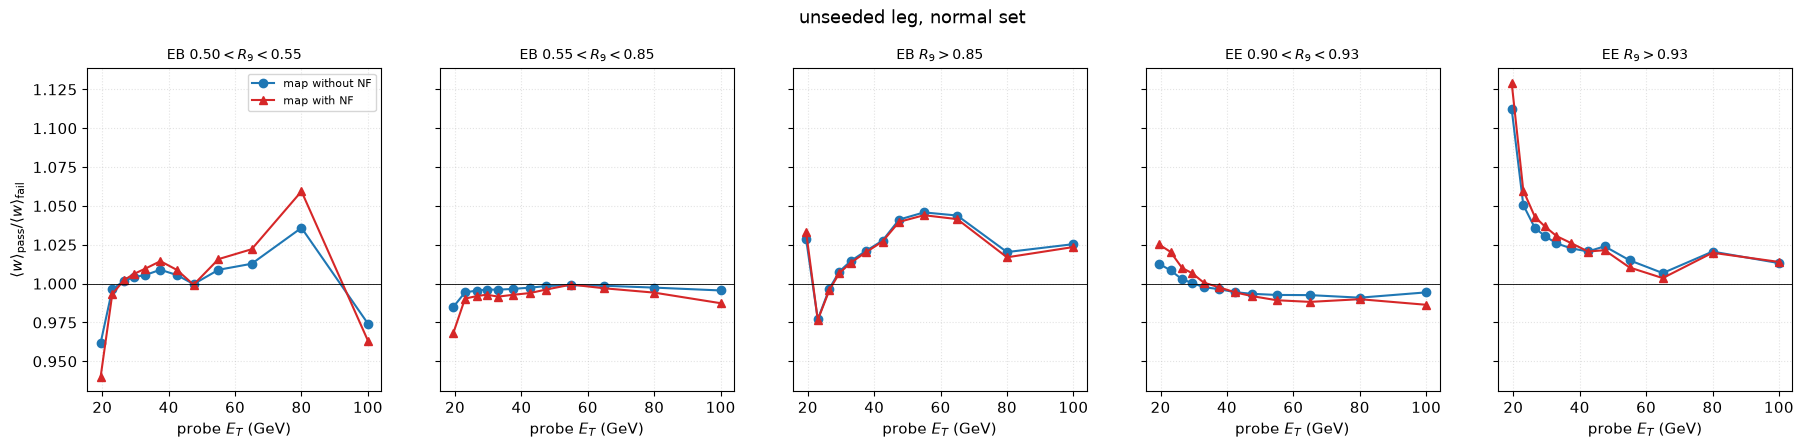

In [14]:
# [J2] Mean weight of passing vs failing probes
for leg in LEGS:
    fig, axs = plt.subplots(1, 5, figsize=(22, 4.2), sharey=True)
    for a, cat in zip(axs, CATS):
        g = K[(K.set == 'normal') & (K.leg == leg) & (K.cat == cat)].sort_values('et_lo')
        x, _ = xpos(leg, g.et_lo.values, g.et_hi.values)
        a.plot(x, g.wpass_old / g.wfail_old, '-o', color=SRC['repo']['color'], label='map without NF')
        a.plot(x, g.wpass_new / g.wfail_new, '-^', color=SRC['local']['color'], label='map with NF')
        a.axhline(1, color='k', lw=0.6); a.set_title(CAT_TEX[cat], fontsize=10); a.set_xlabel(r'probe $E_T$ (GeV)')
    axs[0].set_ylabel(r'$\langle w\rangle_{\rm pass}/\langle w\rangle_{\rm fail}$'); axs[0].legend(fontsize=8)
    fig.suptitle(f'{LEG_TEX[leg]} leg, normal set', y=1.02)
    save(fig, PLOTS / 'why' / f'wpass_over_wfail_{leg}')
    plt.show()

## [J3] Same weights, two selections: normal vs fullPath
The normal and fullPath sets use the same map and the same probes up to the extra `probe_passFullPath == 1` requirement. Per bin: fitted shift (local − repo) in fullPath vs normal (left) and counting shift fullPath vs normal (right). Weight-driven shifts would appear in both selections.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/normal_vs_fullPath_shifts.pdf


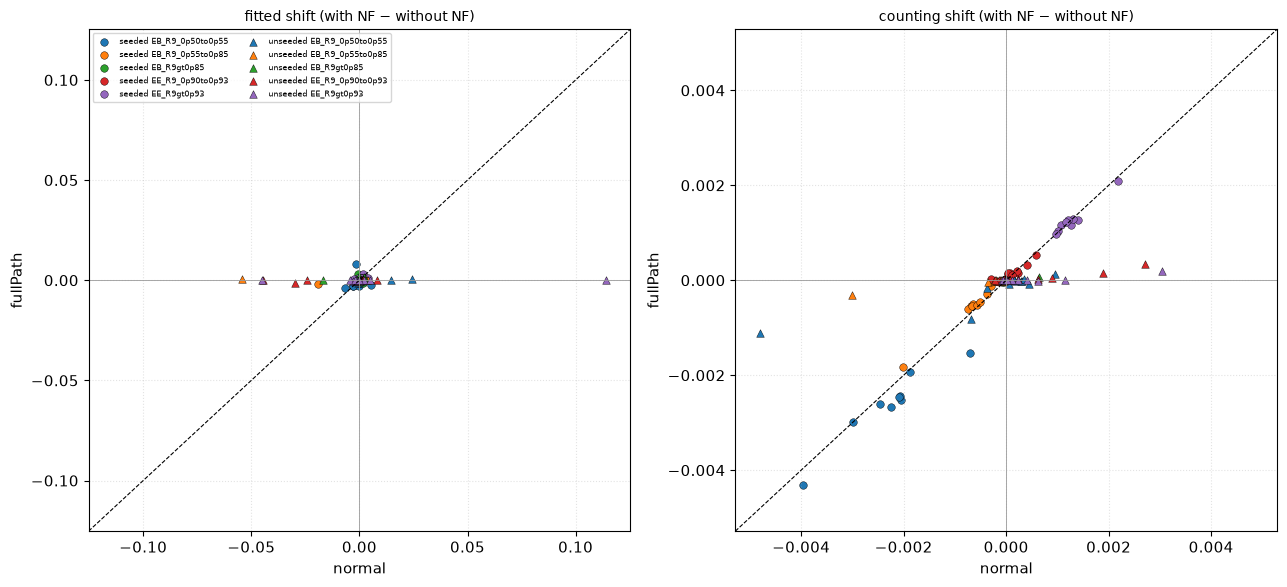

max |fitted shift|: normal 0.11388  fullPath 0.00833
max |counting shift|: normal 0.0048  fullPath 0.00432


In [15]:
# [J3] Same weights, two selections: normal vs fullPath
kk = K.pivot_table(index=['leg', 'cat', 'et_lo', 'et_hi'], columns='set', values=['d_local_repo', 'd_count']).reset_index()
kk.columns = ['_'.join(c).strip('_') for c in kk.columns]
fig, axs = plt.subplots(1, 2, figsize=(13, 6))
for a, col, ttl in ((axs[0], 'd_local_repo', 'fitted shift (with NF − without NF)'), (axs[1], 'd_count', 'counting shift (with NF − without NF)')):
    for leg, mk in (('seed', 'o'), ('unseed', '^')):
        for cat, c in zip(CATS, plt.cm.tab10.colors):
            g = kk[(kk.leg == leg) & (kk.cat == cat)]
            a.scatter(g[f'{col}_normal'], g[f'{col}_fullPath'], marker=mk, color=c, s=30, edgecolor='k', lw=0.3, label=f'{LEG_TEX[leg]} {cat}')
    lim = max(kk[f'{col}_normal'].abs().max(), kk[f'{col}_fullPath'].abs().max()) * 1.1
    a.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8); a.axhline(0, color='0.6', lw=0.6); a.axvline(0, color='0.6', lw=0.6)
    a.set_xlim(-lim, lim); a.set_ylim(-lim, lim); a.set_xlabel('normal'); a.set_ylabel('fullPath'); a.set_title(ttl, fontsize=10)
axs[0].legend(fontsize=6, ncol=2)
fig.tight_layout()
save(fig, PLOTS / 'why' / 'normal_vs_fullPath_shifts')
plt.show()
print('max |fitted shift|: normal', kk.d_local_repo_normal.abs().max().round(5), ' fullPath', kk.d_local_repo_fullPath.abs().max().round(5))
print('max |counting shift|: normal', kk.d_count_normal.abs().max().round(5), ' fullPath', kk.d_count_fullPath.abs().max().round(5))

## [K] Cell decomposition of the largest fitted shifts
For the 6 bins with the largest |local − repo| (normal set), the first-order contribution of each map cell to the counting shift: δε_c = [(1 − ε)·N_pass,c − ε·N_fail,c]·(w_new,c − w_old,c) / (P + F), evaluated at the old map. The sum over cells is printed next to the exact counting shift as a check of the linearisation.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/cell_decomposition_top6.pdf


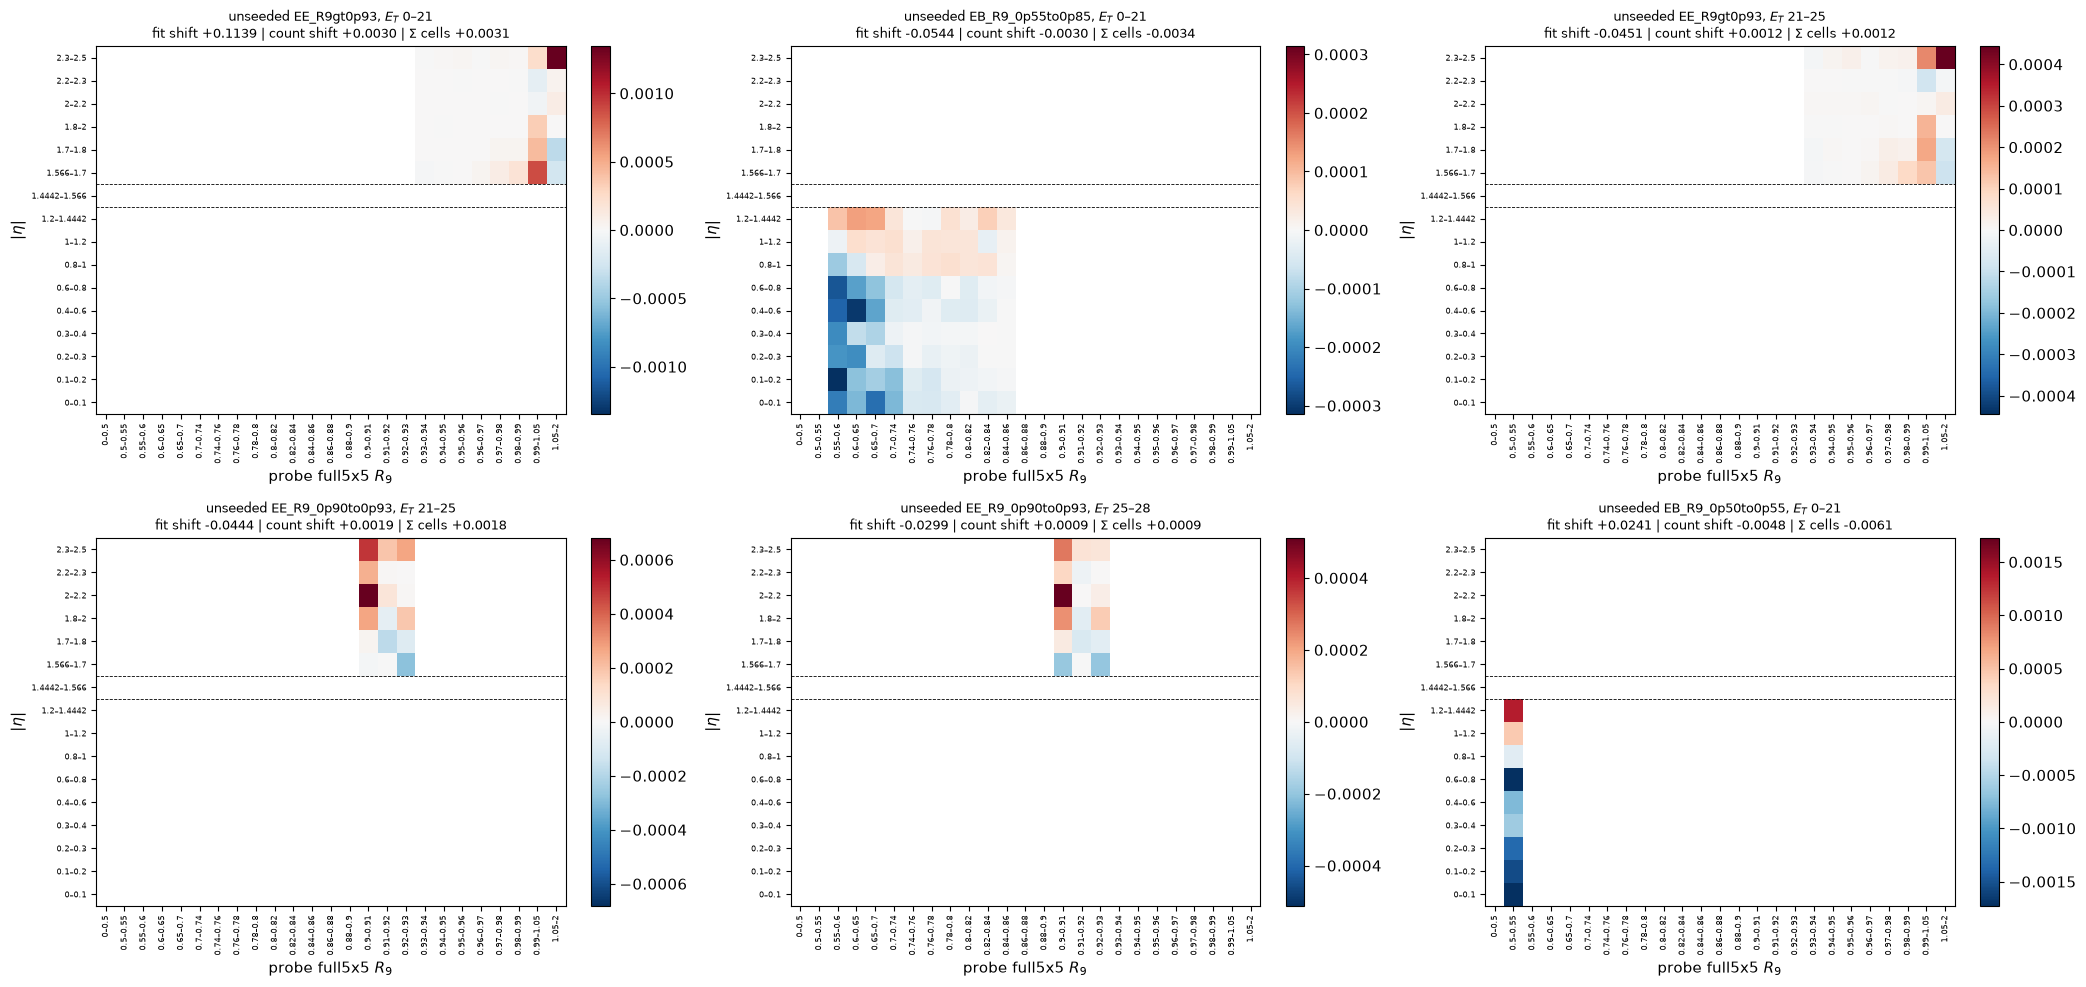

,leg,cat,et_lo,et_hi,fit_shift,count_shift,linear_sum,top_cell
0,unseed,EE_R9gt0p93,0.0,21.0,0.11388,0.00305,0.00309,"R9 1.05–2, |eta| 2.3–2.5"
1,unseed,EB_R9_0p55to0p85,0.0,21.0,-0.05442,-0.00302,-0.00343,"R9 0.55–0.6, |eta| 0.1–0.2"
2,unseed,EE_R9gt0p93,21.0,25.0,-0.04507,0.00115,0.00116,"R9 1.05–2, |eta| 2.3–2.5"
3,unseed,EE_R9_0p90to0p93,21.0,25.0,-0.04439,0.00188,0.00182,"R9 0.9–0.91, |eta| 2–2.2"
4,unseed,EE_R9_0p90to0p93,25.0,28.0,-0.02987,0.00089,0.00086,"R9 0.9–0.91, |eta| 2–2.2"
5,unseed,EB_R9_0p50to0p55,0.0,21.0,0.02414,-0.00480,-0.00611,"R9 0.5–0.55, |eta| 0.6–0.8"


In [16]:
# [K] Cell decomposition of the largest fitted shifts
top = K[K.set == 'normal'].reindex(K[K.set == 'normal'].d_local_repo.abs().sort_values(ascending=False).index).head(6)
fig, axs = plt.subplots(2, 3, figsize=(21, 10))
dec_rows = []
for a, r in zip(axs.flat, top.itertuples()):
    d = C[('normal', r.leg, r.cat)]; ib = int(np.where(d['pt'][:-1] == r.et_lo)[0][0])
    nf, np_ = d['n'][ib, 0].astype(float), d['n'][ib, 1].astype(float)
    P, F = (np_ * MO).sum(), (nf * MO).sum(); eps = P / (P + F)
    contrib = ((1 - eps) * np_ - eps * nf) * (MN - MO) / (P + F)
    lim = np.abs(contrib).max()
    im = a.imshow(np.where((np_ + nf) > 0, contrib, np.nan).T, origin='lower', aspect='auto', cmap='RdBu_r', norm=TwoSlopeNorm(0, -lim, lim))
    grid_axes(a); fig.colorbar(im, ax=a, fraction=0.04)
    hi = r.et_hi if r.et_hi < 1e5 else np.inf
    a.set_title(f'{LEG_TEX[r.leg]} {r.cat}, $E_T$ {r.et_lo:g}–{hi:g}\nfit shift {r.d_local_repo:+.4f} | count shift {r.d_count:+.4f} | Σ cells {contrib.sum():+.4f}', fontsize=9)
    dec_rows.append(dict(leg=r.leg, cat=r.cat, et_lo=r.et_lo, et_hi=r.et_hi, fit_shift=r.d_local_repo, count_shift=r.d_count, linear_sum=contrib.sum(),
                         top_cell=f'R9 {r9lab[np.unravel_index(np.abs(contrib).argmax(), contrib.shape)[0]]}, |eta| {etalab[np.unravel_index(np.abs(contrib).argmax(), contrib.shape)[1]]}'))
fig.tight_layout()
save(fig, PLOTS / 'why' / 'cell_decomposition_top6')
plt.show()
DEC = pd.DataFrame(dec_rows); DEC.round(5)

## [L] Weight distributions and effective statistics
Left: distribution of per-probe weights over all selected probes (normal set) for each map — built from cell counts × cell value. Right: effective sample size of the **failing** probes, N_eff = (Σw)²/Σw², new/old per bin — the failing-probe fit is the one that moved in the fit-plot pairs.

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/plots/why/weights_and_neff.pdf


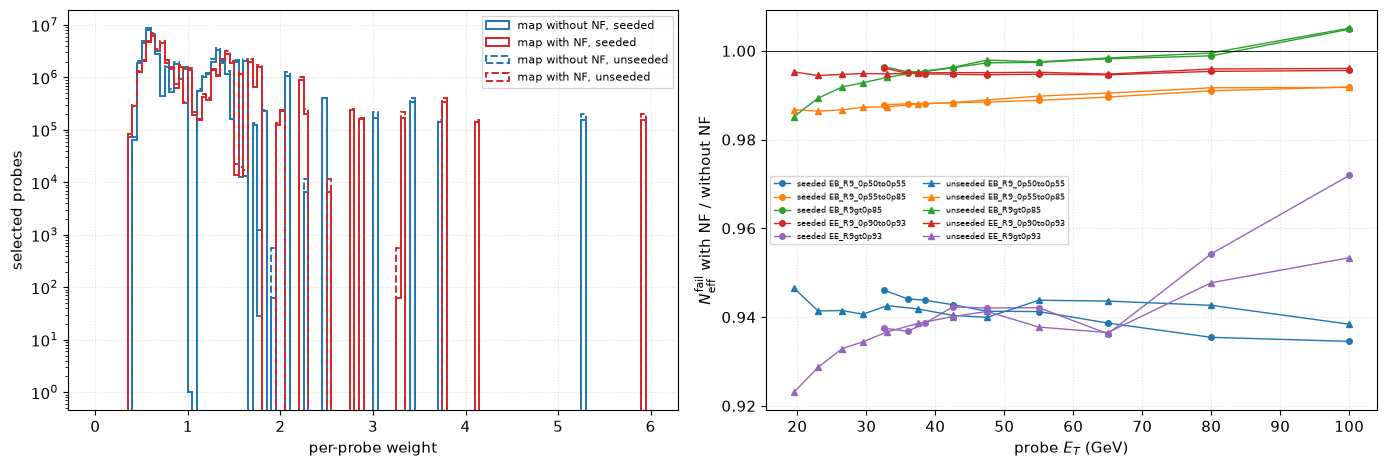

In [17]:
# [L] Weight distributions and effective statistics
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for leg, ls in (('seed', '-'), ('unseed', '--')):
    occ = sum(OCC[(leg, c)] for c in CATS)
    for tag, M, col in (('without NF', MO, SRC['repo']['color']), ('with NF', MN, SRC['local']['color'])):
        axs[0].hist(M.ravel(), bins=np.linspace(0, 6, 121), weights=occ.ravel(), histtype='step', color=col, ls=ls, lw=1.4, label=f'map {tag}, {LEG_TEX[leg]}')
axs[0].set_yscale('log'); axs[0].set_xlabel('per-probe weight'); axs[0].set_ylabel('selected probes'); axs[0].legend(fontsize=8)
k = K[K.set == 'normal']
for leg, mk in (('seed', 'o'), ('unseed', '^')):
    for cat, col in zip(CATS, plt.cm.tab10.colors):
        g = k[(k.leg == leg) & (k.cat == cat)].sort_values('et_lo')
        x, _ = xpos(leg, g.et_lo.values, g.et_hi.values)
        axs[1].plot(x, g.neff_fail_new / g.neff_fail_old, marker=mk, color=col, lw=1, ms=4, label=f'{LEG_TEX[leg]} {cat}')
axs[1].axhline(1, color='k', lw=0.6); axs[1].set_xlabel(r'probe $E_T$ (GeV)'); axs[1].set_ylabel(r'$N_{\rm eff}^{\rm fail}$ with NF / without NF'); axs[1].legend(fontsize=6, ncol=2)
fig.tight_layout()
save(fig, PLOTS / 'why' / 'weights_and_neff')
plt.show()

## [M] Numbers for slides
Every number quoted on a slide is printed here, so the deck can be checked against this output.

In [18]:
# [M] Numbers for slides
S = {}
for st in SETS:
    w = W[W.set == st]
    S[st] = dict(mean_d_local_repo=w.d_local_repo.mean(), mean_abs_d_local_repo=w.d_local_repo.abs().mean(), max_abs_d_local_repo=w.d_local_repo.abs().max(),
                 n_abs_d_gt_0p01=int((w.d_local_repo.abs() > 0.01).sum()), n_bins=len(w),
                 n_abs_pull_gt_3=int((w.pull_local_repo.abs() > 3).sum()), max_abs_pull=w.pull_local_repo.abs().max(),
                 mean_abs_d_2023_repo=w.d_2023_repo.abs().mean(), mean_abs_d_2023_local=w.d_2023_local.abs().mean(),
                 max_abs_d_count=K[K.set == st].d_count.abs().max(), mean_abs_d_count=K[K.set == st].d_count.abs().mean(),
                 corr_fit_count=float(np.corrcoef(K[K.set == st].d_count, K[K.set == st].d_local_repo)[0, 1]))
    for leg in LEGS:
        ww = w[w.leg == leg]
        S[st][f'{leg}_max_abs_d_local_repo'] = ww.d_local_repo.abs().max()
        S[st][f'{leg}_n_abs_d_gt_0p01'] = int((ww.d_local_repo.abs() > 0.01).sum())
        S[st][f'{leg}_n_abs_d_gt_0p01_ET_lt_31'] = int(((ww.d_local_repo.abs() > 0.01) & (ww.et_hi <= 31)).sum())
S['maps'] = dict(old_min=float(MO.min()), old_max=float(MO.max()), new_min=float(MN.min()), new_max=float(MN.max()),
                 n_old_eq_1=int((MO == 1).sum()), n_new_eq_0=int((MN == 0).sum()),
                 ratio_min=float(np.nanmin(RATIO)), ratio_max=float(np.nanmax(RATIO)))
S['occupancy'] = occ_summary.round(6).to_dict(orient='records')
S['decomposition_top6'] = DEC.round(6).to_dict(orient='records')
(ROOT_DIR / 'data' / 'slide_numbers.json').write_text(json.dumps(S, indent=1, default=float))
print(ROOT_DIR / 'data' / 'slide_numbers.json')
print(json.dumps({k: v for k, v in S.items() if k in SETS or k == 'maps'}, indent=1, default=float))

/home/santanu/Desktop/HLT_2024_lowmass_final_with_NR_eta_r9_rw/etaR9_map_study/data/slide_numbers.json
{
 "normal": {
  "mean_d_local_repo": -0.0006657142857142853,
  "mean_abs_d_local_repo": 0.004768571428571435,
  "max_abs_d_local_repo": 0.11387999999999998,
  "n_abs_d_gt_0p01": 10,
  "n_bins": 105,
  "n_abs_pull_gt_3": 0,
  "max_abs_pull": 1.6463167013354187,
  "mean_abs_d_2023_repo": 0.010462380952380957,
  "mean_abs_d_2023_local": 0.010360285714285721,
  "max_abs_d_count": 0.004804480595984595,
  "mean_abs_d_count": 0.0006492575127182762,
  "corr_fit_count": 0.178187398247937,
  "seed_max_abs_d_local_repo": 0.0192500000000001,
  "seed_n_abs_d_gt_0p01": 1,
  "seed_n_abs_d_gt_0p01_ET_lt_31": 0,
  "unseed_max_abs_d_local_repo": 0.11387999999999998,
  "unseed_n_abs_d_gt_0p01": 9,
  "unseed_n_abs_d_gt_0p01_ET_lt_31": 8
 },
 "fullPath": {
  "mean_d_local_repo": -2.4857142857139698e-05,
  "mean_abs_d_local_repo": 0.0006475238095238169,
  "max_abs_d_local_repo": 0.008329999999999949,
  "n